# SwiftRoute Logistics - Delivery Delay Prediction
## DSAI Mini Coursework

**Student name**: Bui Ngoc Anh  
**Email**: anh.bui737@gmail.com  
**Discord username**: superspy737  
**Submission date**: 2026-10-22

---

### Mark Scheme

| Section | Marks |
|---|---|
| 1 | 10 |
| 2 | 3 |
| 3 | 10 |
| 4 | 12 |
| 5 | 15 |
| 6 | 15 |
| 7 | 8 |
| 8 | 12 |
| 9 | 5 |
| Extension | 10 |
| **Total** | **100** |


---
# SECTION 1 - Understanding the Problem *(10 marks)*

**1.1** *(1 mark)* In one sentence, describe what SwiftRoute is trying to predict and why it matters.

SwiftRoute wants to predict at pickup which parcels are likely to arrive late, so Operations can focus its limited intervention capacity on the highest-risk 15 % and reduce late deliveries, SLA penalties and lost clients.

---

**1.2** *(2 marks)* Is this a classification or regression problem? What is the target variable? What does one row in the training data represent?

This is **supervised binary classification**. The target variable is `is_delayed` (1 = delivered outside the promised window, 0 = on time). **One row represents one shipment**: a parcel collected on one pickup date, on one route, with one carrier and one service tier, together with its weight, volume and declared value.

---

**1.3** *(3 marks)* Only ~12% of shipments are delayed. Explain why **accuracy** is a misleading metric here. What metric will you use instead, and what does it measure in the context of delivery operations?

Predicting “on time” for every shipment gives **about 88 % accuracy while finding zero delays**, so accuracy rewards a model that never flags anything. It also depends on a cut-off for turning scores into labels, whereas the operational rule here is a fixed 15 % budget rather than a 0.5 threshold.

- **ROC-AUC** measures how well the model ranks delayed shipments above on-time shipments across all thresholds: the probability that a randomly chosen delayed shipment scores higher than a randomly chosen on-time one. It is not the percentage classified correctly. Above 0.75 is usable and above 0.80 strong for this problem.
- **Delay capture rate at 15 %** is the share of all actual delays that fall within the 15 % of shipments flagged, i.e. recall at the fixed intervention budget. Random selection captures 15 % on average; a higher capture rate means more delays found for the same workload. Preventing them still requires an effective intervention.

---

**1.4** *(2 marks)* The Operations team can only intervene on the top **15%** of highest-risk shipments. Describe the two types of mistake your model can make, and explain which is more costly to SwiftRoute.

- **False negative:** a delayed shipment is not flagged, so nothing is done and the SLA penalty, handling cost and damage to the client relationship are incurred.
- **False positive:** a flagged shipment would have arrived on time anyway, so the intervention (re-route, tier upgrade, pre-alert) consumes time or money without preventing a delay.

The **false negative is the costlier mistake**: each avoided delay is assumed to save £45 in penalties and handling, and repeated misses threaten contract renewals, whereas a false positive is a bounded operational cost. Because the budget is fixed at 15 %, the model cannot reduce missed delays by flagging more shipments; better ranking is the only lever. The exact trade-off depends on the intervention cost, which is not yet known.

---

**1.5** *(2 marks)* The `weather_events` table stores disruptions as date ranges (start_date to end_date) by region. Explain the challenge of joining this to `shipments`, and what logic is needed.

Each shipment needs one weather value for its origin region and one for its destination region, both on the pickup date, and the weather table has no shipment key, so an ordinary equality join does not work:

1. Match on region and keep only events where `start_date <= pickup_date <= end_date` (a range condition, including both boundary dates).
2. Several overlapping events can match one shipment, so aggregate to one row per shipment by taking the maximum severity; otherwise the join would duplicate shipments.
3. Map each regional result back to the shipment and fill zero when no event matches.

Section 4.3 implements this with a region merge, a date filter and the maximum severity grouped by shipment ID. Destination weather means conditions in that region at pickup, not conditions observed when the parcel arrives.


---
# SECTION 2 - Setup & Data Loading *(3 marks)*

In [1]:
# *(1 mark)* Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 160)


In [2]:
# *(2 marks)* Load all four CSV files. Print shape and first few rows of each.
shipments = pd.read_csv('data/shipments.csv', parse_dates=['pickup_date'])
routes    = pd.read_csv('data/routes.csv')
carriers  = pd.read_csv('data/carriers.csv')
weather   = pd.read_csv('data/weather_events.csv', parse_dates=['start_date','end_date'])

# The dates are parsed at load time on purpose: the weather join (4.3) compares dates and
# the monthly delay-rate plot (3.2) resamples by pickup_date.
for name, df in [('shipments', shipments), ('routes', routes), ('carriers', carriers), ('weather', weather)]:
    print(f'{name:10s} shape = {df.shape}')
    display(df.head(3))


shipments  shape = (10025, 12)


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0


routes     shape = (60, 7)


,route_id,origin_region,dest_region,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days
0,R0001,London,North_East,480,3,0.2471,2.92
1,R0002,Scotland,Yorkshire,139,1,0.1617,1.85
2,R0003,South_West,Midlands,191,1,0.1449,1.71


carriers   shape = (8, 7)


,carrier_id,carrier_name,tier_coverage,reliability_score,capacity_utilisation,avg_delay_mins,n_active_routes
0,C01,FastTrack,all,0.9508,0.5926,78.2,17
1,C02,PrimeMove,all,0.9049,0.6838,82.2,25
2,C03,SureDeliver,all,0.8605,0.6675,35.0,8


weather    shape = (265, 6)


,event_id,region,event_type,severity,start_date,end_date
0,W00001,Midlands,high_wind,2,2024-01-03,2024-01-05
1,W00002,Yorkshire,snow,1,2024-01-26,2024-01-30
2,W00003,London,flood,1,2024-01-15,2024-01-18


---
# SECTION 3 - Exploring the Data (EDA) *(10 marks)*

### 3.1 Data Quality Check *(3 marks)*

In [3]:
# *(3 marks)* Check: dtypes, null counts, duplicates, referential integrity,
# and the overall delay rate.

# --- dtypes and nulls ---
print(shipments.dtypes, '\n')
print('columns with nulls in shipments:')
print(shipments.isna().sum()[lambda s: s > 0])
print('\nnulls in routes / carriers / weather:', routes.isna().sum().sum(), carriers.isna().sum().sum(), weather.isna().sum().sum())

# --- duplicates: exact rows, duplicate ids, and duplicates ignoring the id ---
non_id = [c for c in shipments.columns if c != 'shipment_id']
print('\nexact duplicate rows        :', shipments.duplicated().sum())
print('duplicate shipment_id       :', shipments['shipment_id'].duplicated().sum())
print('duplicates ignoring the id  :', shipments.duplicated(subset=non_id).sum())

# --- referential integrity between the four tables ---
print('\nroutes missing from routes.csv    :', (~shipments['route_id'].isin(routes['route_id'])).sum())
print('carriers missing from carriers.csv:', (~shipments['carrier_id'].isin(carriers['carrier_id'])).sum())
chk = shipments.merge(routes[['route_id','origin_region','dest_region']], on='route_id', suffixes=('', '_r'))
print('route origin/dest mismatches      :', ((chk.origin_region != chk.origin_region_r) | (chk.dest_region != chk.dest_region_r)).sum())
chk = shipments.merge(carriers[['carrier_id','tier_coverage']], on='carrier_id')
bad = (((chk.tier_coverage == 'express_only') & (chk.service_tier != 'express'))
       | ((chk.tier_coverage == 'standard_economy') & (chk.service_tier == 'express')))
print('carrier/tier coverage violations  :', bad.sum())
print('weather regions == shipment regions:', set(weather.region) == set(shipments.origin_region) | set(shipments.dest_region))
print('weather events with end < start   :', (weather.end_date < weather.start_date).sum())

# --- target, time range, numeric summary ---
print(f"\ndelay rate: {shipments['is_delayed'].mean():.3%}  ({shipments['is_delayed'].sum():,} of {len(shipments):,} shipments)")
print('label values:', sorted(shipments['is_delayed'].unique()),
      '| pickups', shipments.pickup_date.min().date(), '→', shipments.pickup_date.max().date())
display(shipments.describe().T.round(2))

# --- compare missing and recorded values; these checks do not establish why data are missing ---
for col in ['weight_kg', 'declared_value']:
    miss = shipments[col].isna()
    print(f'{col:15s} missing {miss.sum():4d} ({miss.mean():.1%}) | delay rate when missing '
          f'{shipments.loc[miss, "is_delayed"].mean():.3f} vs when present {shipments.loc[~miss, "is_delayed"].mean():.3f}')
print('share of missing weight by tier:', shipments.groupby('service_tier')['weight_kg'].apply(lambda s: s.isna().mean()).round(3).to_dict())


shipment_id                  str
pickup_date       datetime64[us]
origin_region                str
dest_region                  str
service_tier                 str
carrier_id                   str
route_id                     str
weight_kg                float64
volume_cm3                 int64
declared_value           float64
is_business                int64
is_delayed                 int64
dtype: object 

columns with nulls in shipments:
weight_kg         320
declared_value    507
dtype: int64

nulls in routes / carriers / weather: 0 0 0

exact duplicate rows        : 0
duplicate shipment_id       : 0
duplicates ignoring the id  : 25

routes missing from routes.csv    : 0
carriers missing from carriers.csv: 0
route origin/dest mismatches      : 0
carrier/tier coverage violations  : 0
weather regions == shipment regions: True
weather events with end < start   : 0

delay rate: 11.910%  (1,194 of 10,025 shipments)
label values: [np.int64(0), np.int64(1)] | pickups 2024-01-01 → 2026-06-

,count,mean,min,25%,50%,75%,max,std
pickup_date,10025,2025-03-27 18:05:12.418952,2024-01-01 00:00:00,2024-08-12 00:00:00,2025-03-30 00:00:00,2025-11-10 00:00:00,2026-06-19 00:00:00,NaN
weight_kg,9705.0,5.055685,0.1,1.42,3.45,7.05,50.0,5.12135
volume_cm3,10025.0,3548.655761,20.0,822.0,2123.0,4773.0,56687.0,4137.762374
declared_value,9518.0,80.20106,5.0,23.38,55.35,111.375,892.46,78.93161
is_business,10025.0,0.647481,0.0,0.0,1.0,1.0,1.0,0.477778
is_delayed,10025.0,0.119102,0.0,0.0,0.0,0.0,1.0,0.323925


weight_kg       missing  320 (3.2%) | delay rate when missing 0.109 vs when present 0.119
declared_value  missing  507 (5.1%) | delay rate when missing 0.148 vs when present 0.118
share of missing weight by tier: {'economy': 0.031, 'express': 0.035, 'standard': 0.031}


**Commentary** - List quality issues and how you will handle each.

| Issue | Finding | Handling |
|---|---|---|
| Duplicate records | No exact duplicates or repeated IDs, but 25 rows match on every column except `shipment_id`. | Treat as duplicates: compare all non-ID columns and keep the first occurrence (4.1). |
| Missing weight | 320 values missing (3.2 %); delay rate 10.9 % when missing versus 11.9 % when recorded. | Impute the training-set median inside the model pipeline and keep a `weight_missing` flag. |
| Missing declared value | 507 values missing (5.1 %); delay rate 14.8 % versus 11.8 %. | Keep the rows; impute the training-set median and add a `value_missing` flag, since the missingness itself carries information. |
| Lookup consistency | All route/carrier IDs match their tables; shipment regions agree with route regions; carrier tier coverage is respected; weather regions and date ranges are valid. | No cleaning needed; use many-to-one joins and check that row counts are unchanged in Section 4. |
| Target | 11.9 % delayed (1,194 of 10,025); labels are 0/1 with none missing. | Stratified splits, class weights, and AUC plus capture at the fixed 15 % budget instead of accuracy. |
| Outliers / skew | Long upper tails: weight up to 50 kg, value up to about £890, but plausible parcels. | Retain the values; add log-transformed versions for the linear model. |
| Dates | 2024-01-01 to 2026-06-19, roughly 1,000 shipments per quarter, no gaps. | Derive calendar features; use a later-period check in Section 6. |

Imputation and scaling are fitted on training rows only, inside the model pipeline, so validation data never influence them.


### 3.2 Distribution of Key Columns *(2 marks)*

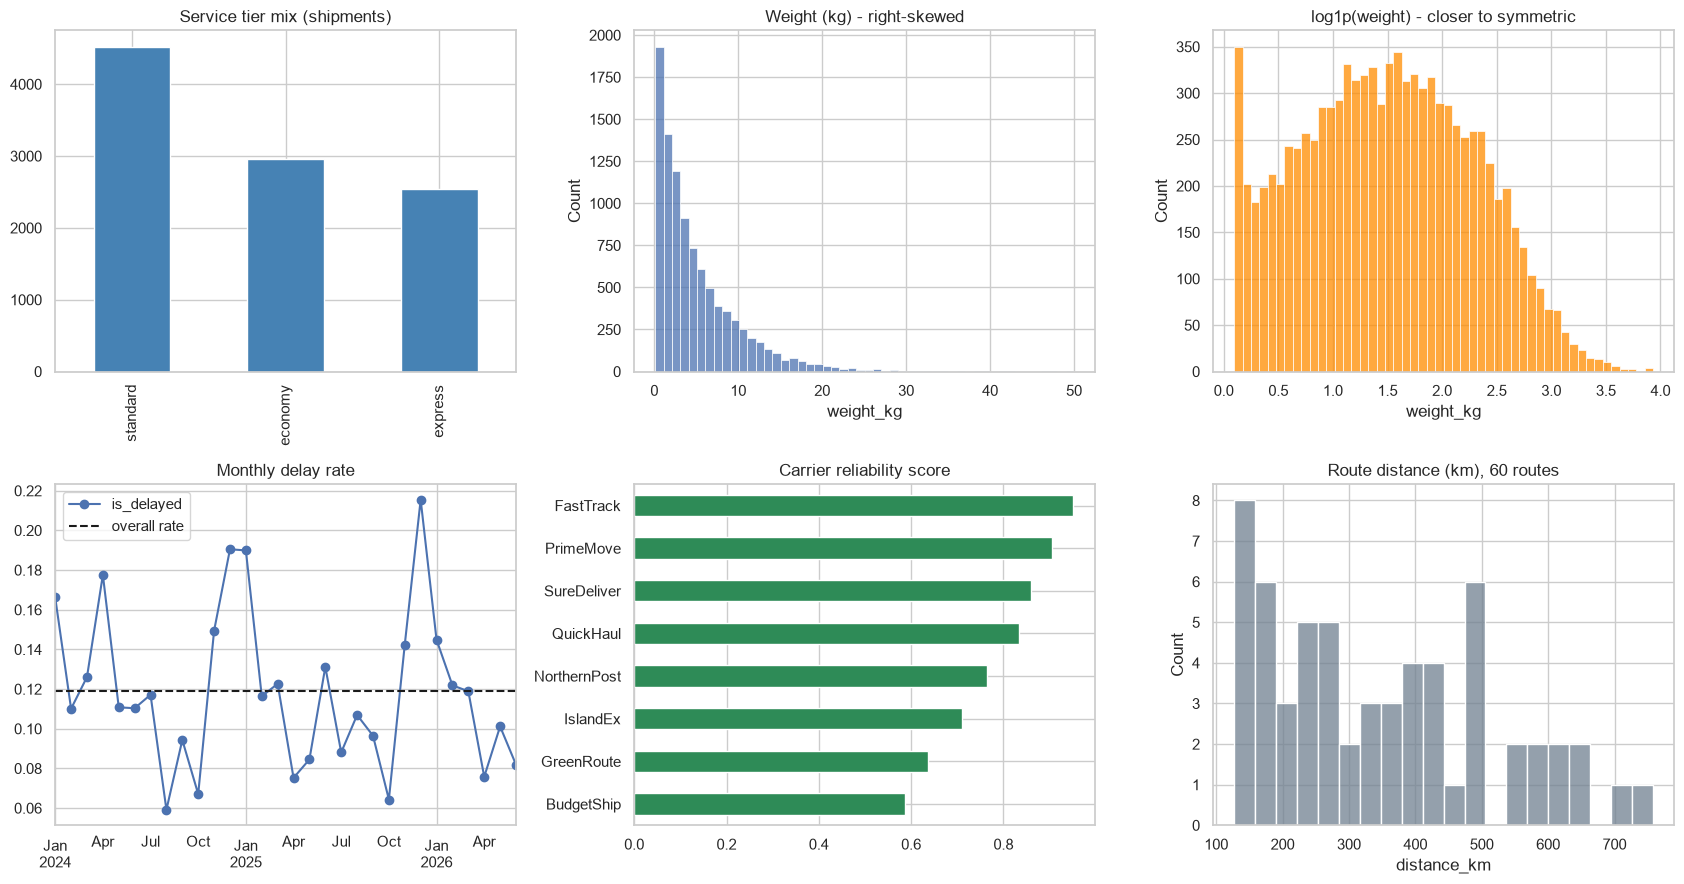

{'standard': 0.451, 'economy': 0.296, 'express': 0.253}
weight_kg  median / mean / max: 3.45 5.06 50.0
volume_cm3 median / mean / max: 2123.0 3548.7 56687
delay rate by quarter of the year (seasonality):
{1: 0.136, 2: 0.106, 3: 0.094, 4: 0.139}


,carrier_id,carrier_name,tier_coverage,reliability_score,capacity_utilisation
7,C08,BudgetShip,all,0.5871,0.9049
6,C07,GreenRoute,all,0.6358,0.8606
5,C06,IslandEx,standard_economy,0.7111,0.8689
4,C05,NorthernPost,express_only,0.7640,0.8150
3,C04,QuickHaul,all,0.8332,0.7361
2,C03,SureDeliver,all,0.8605,0.6675
1,C02,PrimeMove,all,0.9049,0.6838
0,C01,FastTrack,all,0.9508,0.5926


In [4]:
# *(2 marks)* Plot: service_tier mix, weight distribution, delay rate over time
# (monthly), carrier reliability scores, route distance distribution.

fig, ax = plt.subplots(2, 3, figsize=(17, 9)); ax = ax.ravel()

shipments['service_tier'].value_counts().plot(kind='bar', ax=ax[0], color='steelblue')
ax[0].set_title('Service tier mix (shipments)'); ax[0].set_xlabel('')

sns.histplot(shipments['weight_kg'].dropna(), bins=50, ax=ax[1]); ax[1].set_title('Weight (kg) - right-skewed')
sns.histplot(np.log1p(shipments['weight_kg'].dropna()), bins=50, ax=ax[2], color='darkorange'); ax[2].set_title('log1p(weight) - closer to symmetric')

monthly = shipments.set_index('pickup_date')['is_delayed'].resample('ME').mean()
monthly.plot(ax=ax[3], marker='o'); ax[3].axhline(shipments.is_delayed.mean(), ls='--', c='k', label='overall rate')
ax[3].set_title('Monthly delay rate'); ax[3].set_xlabel(''); ax[3].legend()

carriers.set_index('carrier_name')['reliability_score'].sort_values().plot(kind='barh', ax=ax[4], color='seagreen')
ax[4].set_title('Carrier reliability score'); ax[4].set_ylabel('')

sns.histplot(routes['distance_km'], bins=20, ax=ax[5], color='slategrey'); ax[5].set_title('Route distance (km), 60 routes')
plt.tight_layout(); plt.show()

print(shipments['service_tier'].value_counts(normalize=True).round(3).to_dict())
print('weight_kg  median / mean / max:', shipments.weight_kg.median(), round(shipments.weight_kg.mean(), 2), shipments.weight_kg.max())
print('volume_cm3 median / mean / max:', shipments.volume_cm3.median(), round(shipments.volume_cm3.mean(), 1), shipments.volume_cm3.max())
print('delay rate by quarter of the year (seasonality):')
print(shipments.groupby(shipments.pickup_date.dt.quarter)['is_delayed'].mean().round(3).to_dict())
display(carriers[['carrier_id','carrier_name','tier_coverage','reliability_score','capacity_utilisation']].sort_values('reliability_score'))


**Commentary** - Two interesting observations.

1. **Delay rates vary by season.** Pooling quarters across years, Q4 and Q1 have delay rates of about 13.9 % and 13.6 %, versus 9.4 % in Q3: roughly 50 % higher in relative terms. This supports testing calendar features and allowing for seasonality in monitoring.
2. **Carrier reliability and capacity use differ substantially, and the two go together.** Reliability ranges from 0.59 for C08 BudgetShip to 0.95 for C01 FastTrack, and the two least reliable carriers (C07 GreenRoute, C08 BudgetShip) also run at the highest capacity utilisation (0.86 and 0.90).


### 3.3 Which Factors Are Related to Delays? *(3 marks)*

--- by service tier ---
              delay_rate     n
service_tier                  
express            0.166  2540
standard           0.108  4522
economy            0.096  2963

--- by carrier (with reliability score) ---
            delay_rate     n  carrier_name  reliability_score  capacity_utilisation
carrier_id                                                                         
C01              0.038  1381     FastTrack             0.9508                0.5926
C02              0.043  1464     PrimeMove             0.9049                0.6838
C03              0.052  1425   SureDeliver             0.8605                0.6675
C04              0.076  1390     QuickHaul             0.8332                0.7361
C06              0.119  1088      IslandEx             0.7111                0.8689
C05              0.145   373  NorthernPost             0.7640                0.8150
C07              0.213  1407    GreenRoute             0.6358                0.8606
C08              0.2

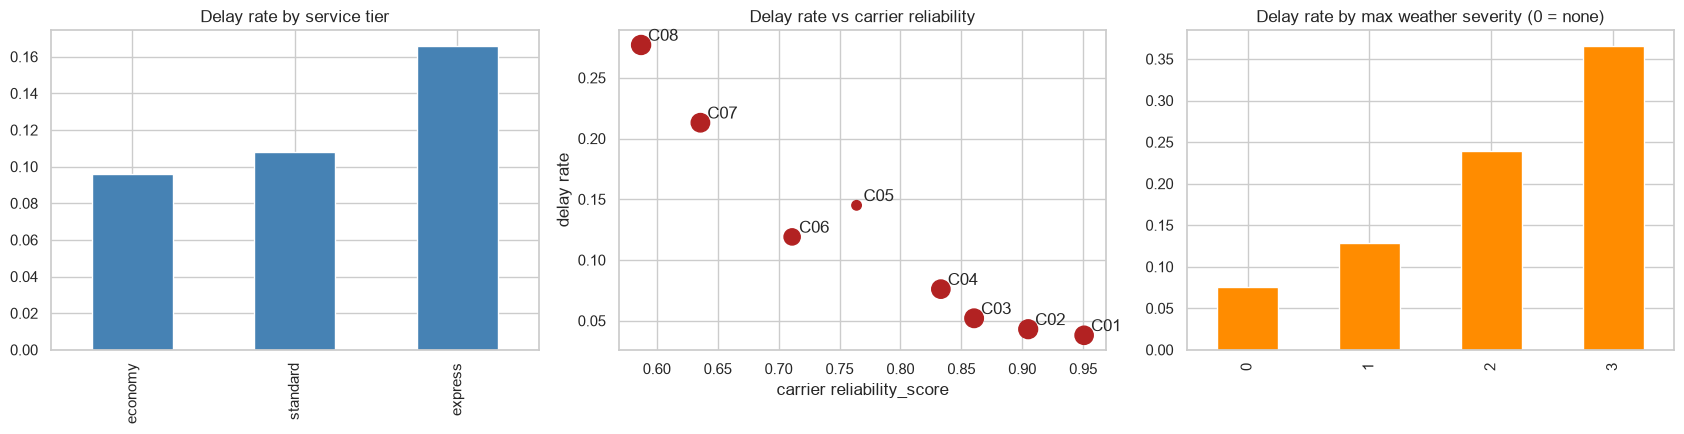

In [5]:
# *(3 marks)* Explore delay rate vs:
# - service_tier
# - carrier (join to carriers.csv for reliability_score)
# - route distance (join to routes.csv)
# - weather (do shipments during weather events delay more?)

# A temporary joined frame for EDA only (the real, documented join is in Section 4).
eda = (shipments.merge(routes.drop(columns=['origin_region','dest_region']), on='route_id', how='left')
                .merge(carriers, on='carrier_id', how='left'))

def rate_by(df, col, bins=None, q=None):
    """Delay rate and group size per value (or per bin) of one column."""
    key = df[col]
    if q: key = pd.qcut(key, q=q, duplicates='drop')
    elif bins is not None: key = pd.cut(key, bins)
    return (df.groupby(key, observed=True)['is_delayed'].agg(['mean','size'])
              .rename(columns={'mean':'delay_rate','size':'n'}).round(3))

print('--- by service tier ---');   print(rate_by(eda, 'service_tier').sort_values('delay_rate', ascending=False))
print('\n--- by carrier (with reliability score) ---')
print(rate_by(eda, 'carrier_id').join(carriers.set_index('carrier_id')[['carrier_name','reliability_score','capacity_utilisation']]).sort_values('delay_rate'))
print('\n--- by route distance (sextiles) ---'); print(rate_by(eda, 'distance_km', q=6))
print('\n--- by number of depot hops ---');  print(rate_by(eda, 'n_depot_hops'))
print('\n--- by historical route delay rate (quintiles) ---'); print(rate_by(eda, 'historical_delay_rate', q=5))
print('\n--- by sender type ---'); print(rate_by(eda, 'is_business'))
print('\n--- by day of week (0 = Monday) ---'); print(rate_by(eda.assign(dow=eda.pickup_date.dt.dayofweek), 'dow'))

# Weather: quick version of the date-range match for EDA (the documented, reusable function is in 4.3).
def max_severity(df, region_col):
    t = df[['shipment_id', region_col, 'pickup_date']].merge(weather, left_on=region_col, right_on='region', how='left')
    t = t[(t.start_date <= t.pickup_date) & (t.pickup_date <= t.end_date)]
    return df['shipment_id'].map(t.groupby('shipment_id')['severity'].max()).fillna(0).astype(int)

eda['sev_origin'] = max_severity(eda, 'origin_region')
eda['sev_dest']   = max_severity(eda, 'dest_region')
eda['weather_any'] = ((eda.sev_origin > 0) | (eda.sev_dest > 0)).astype(int)
eda['max_sev']     = eda[['sev_origin','sev_dest']].max(axis=1)
print('\n--- weather at either end on the pickup date ---'); print(rate_by(eda, 'weather_any'))
print('\n--- by maximum weather severity ---');            print(rate_by(eda, 'max_sev'))

print('\n--- correlation of numeric columns with is_delayed ---')
print(eda[['weight_kg','volume_cm3','declared_value','is_business','distance_km','n_depot_hops',
           'historical_delay_rate','avg_transit_days','reliability_score','capacity_utilisation','max_sev']]
      .corrwith(eda['is_delayed']).round(3).sort_values(key=np.abs, ascending=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
rate_by(eda, 'service_tier')['delay_rate'].sort_values().plot(kind='bar', ax=ax[0], color='steelblue'); ax[0].set_title('Delay rate by service tier'); ax[0].set_xlabel('')
tmp = rate_by(eda, 'carrier_id').join(carriers.set_index('carrier_id')['reliability_score'])
ax[1].scatter(tmp.reliability_score, tmp.delay_rate, s=tmp.n/8, color='firebrick')
for cid, r in tmp.iterrows(): ax[1].annotate(cid, (r.reliability_score, r.delay_rate), textcoords='offset points', xytext=(5, 3))
ax[1].set_xlabel('carrier reliability_score'); ax[1].set_ylabel('delay rate'); ax[1].set_title('Delay rate vs carrier reliability')
rate_by(eda, 'max_sev')['delay_rate'].plot(kind='bar', ax=ax[2], color='darkorange'); ax[2].set_title('Delay rate by max weather severity (0 = none)'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()


**Commentary** - Which factors show the strongest relationship with delays?

The clearest patterns concern the carrier, weather and route:

- **Carrier:** delay rates range from 3.8 % for C01 FastTrack to 27.7 % for C08 BudgetShip, almost perfectly ordered by `reliability_score`.
- **Weather:** a recorded event in either region on the pickup date accompanies 22.7 % delays versus 7.5 % without, and the rate rises with maximum severity: 12.9 %, 23.9 % and 36.6 % for levels 1, 2 and 3. About 29 % of shipments are exposed.
- **Route difficulty:** longer routes and more depot hops accompany higher delay rates (3-hop routes are the worst), and `historical_delay_rate` tracks the observed rates closely.
- **Service tier:** express has 16.6 % delays, standard 10.8 % and economy 9.6 %. The tighter express deadline is a plausible explanation, although these comparisons do not separate it from differences in routes and carriers.
- **Parcel attributes:** weight, volume, declared value and sender type have weak correlations with delay (about 0.01–0.02); only a missing declared value is associated with a higher rate. Day-of-week differences are small.


### 3.4 Which Routes and Carriers Are Riskiest? *(2 marks)*

Top 10 highest-delay routes


,,,n,delay_rate,hist_rate,km,hops,transit_days
route_id,origin_region,dest_region,,,,,,
R0026,London,Wales,177,0.350,0.331,698,3,3.64
R0037,Wales,London,156,0.308,0.279,758,3,3.80
R0055,Wales,South_East,179,0.302,0.352,618,3,3.47
R0043,London,Scotland,165,0.261,0.288,636,3,3.15
R0015,London,Yorkshire,177,0.232,0.286,549,3,3.05
R0001,London,North_East,195,0.215,0.247,480,3,2.92
R0018,Yorkshire,South_East,149,0.208,0.258,446,3,2.65
R0006,Yorkshire,South_West,165,0.206,0.250,412,3,2.67
R0052,Yorkshire,London,172,0.203,0.256,570,3,2.92


corr(observed route delay rate, historical_delay_rate) across the 60 routes: 0.894

Delay rate by carrier


,,n,delay_rate,reliability,utilisation
carrier_id,carrier_name,,,,
C08,BudgetShip,1497,0.277,0.587,0.905
C07,GreenRoute,1407,0.213,0.636,0.861
C05,NorthernPost,373,0.145,0.764,0.815
C06,IslandEx,1088,0.119,0.711,0.869
C04,QuickHaul,1390,0.076,0.833,0.736
C03,SureDeliver,1425,0.052,0.860,0.668
C02,PrimeMove,1464,0.043,0.905,0.684
C01,FastTrack,1381,0.038,0.951,0.593


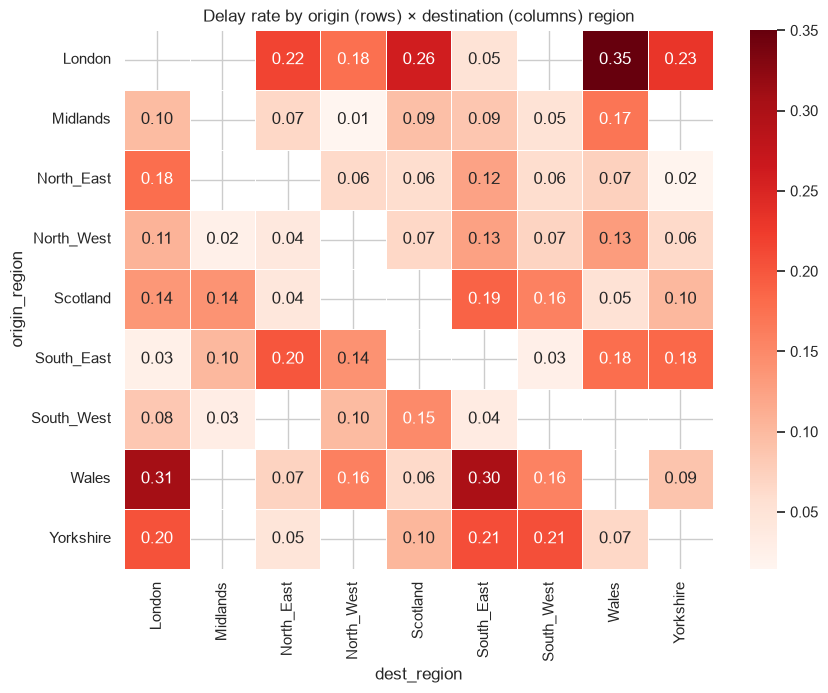

Additional view: delay rate by carrier × service tier


service_tier,economy,express,standard
carrier_id,,,
C01,0.047,0.051,0.026
C02,0.031,0.064,0.038
C03,0.038,0.078,0.047
C04,0.061,0.116,0.064
C05,NaN,0.145,NaN
C06,0.111,NaN,0.126
C07,0.148,0.310,0.207
C08,0.228,0.397,0.238


shipments per carrier × tier


service_tier,economy,express,standard
carrier_id,,,
C01,406.0,351.0,624.0
C02,414.0,390.0,660.0
C03,444.0,361.0,620.0
C04,392.0,354.0,644.0
C05,NaN,373.0,NaN
C06,443.0,NaN,645.0
C07,425.0,316.0,666.0
C08,439.0,395.0,663.0


Route × carrier pairs with the highest observed delay rates (duplicates excluded):


,route_id,origin_region,dest_region,carrier_id,carrier_name,n,delays,delay_rate
335,R0042,Scotland,South_East,C08,BudgetShip,21,15,0.714
340,R0043,London,Scotland,C05,NorthernPost,7,5,0.714
205,R0026,London,Wales,C06,IslandEx,18,12,0.667
206,R0026,London,Wales,C07,GreenRoute,23,14,0.609
343,R0043,London,Scotland,C08,BudgetShip,25,15,0.600
118,R0015,London,Yorkshire,C07,GreenRoute,19,11,0.579
295,R0037,Wales,London,C08,BudgetShip,26,15,0.577
143,R0018,Yorkshire,South_East,C08,BudgetShip,21,12,0.571
207,R0026,London,Wales,C08,BudgetShip,25,14,0.560
119,R0015,London,Yorkshire,C08,BudgetShip,24,13,0.542


Small groups can have extreme rates: read the shipment and delay counts before comparing pairs.
Sensitivity view: pairs with at least 20 shipments (an illustrative reporting cut-off, not a statistical guarantee):


,route_id,origin_region,dest_region,carrier_id,carrier_name,n,delays,delay_rate
335,R0042,Scotland,South_East,C08,BudgetShip,21,15,0.714
206,R0026,London,Wales,C07,GreenRoute,23,14,0.609
343,R0043,London,Scotland,C08,BudgetShip,25,15,0.600
295,R0037,Wales,London,C08,BudgetShip,26,15,0.577
143,R0018,Yorkshire,South_East,C08,BudgetShip,21,12,0.571
207,R0026,London,Wales,C08,BudgetShip,25,14,0.560
119,R0015,London,Yorkshire,C08,BudgetShip,24,13,0.542
438,R0055,Wales,South_East,C07,GreenRoute,26,14,0.538
46,R0006,Yorkshire,South_West,C07,GreenRoute,28,15,0.536
7,R0001,London,North_East,C08,BudgetShip,30,16,0.533


In [6]:
# *(2 marks)* Show: top 10 highest-delay routes, delay rate by carrier,
# and a heatmap of delay rate by origin x destination region.

route_tbl = (eda.groupby(['route_id','origin_region','dest_region'])
               .agg(n=('is_delayed','size'), delay_rate=('is_delayed','mean'),
                    hist_rate=('historical_delay_rate','first'), km=('distance_km','first'),
                    hops=('n_depot_hops','first'), transit_days=('avg_transit_days','first'))
               .sort_values('delay_rate', ascending=False))
print('Top 10 highest-delay routes'); display(route_tbl.head(10).round(3))
print('corr(observed route delay rate, historical_delay_rate) across the 60 routes:',
      round(route_tbl[['delay_rate','hist_rate']].corr().iloc[0, 1], 3))

carrier_tbl = (eda.groupby(['carrier_id','carrier_name'])
                 .agg(n=('is_delayed','size'), delay_rate=('is_delayed','mean'),
                      reliability=('reliability_score','first'), utilisation=('capacity_utilisation','first'))
                 .sort_values('delay_rate', ascending=False))
print('\nDelay rate by carrier'); display(carrier_tbl.round(3))

piv = eda.pivot_table(index='origin_region', columns='dest_region', values='is_delayed', aggfunc='mean')
plt.figure(figsize=(9.5, 7)); sns.heatmap(piv, annot=True, fmt='.2f', cmap='Reds', linewidths=.5)
plt.title('Delay rate by origin (rows) × destination (columns) region'); plt.show()

print('Additional view: delay rate by carrier × service tier')
ct = eda.pivot_table(index='carrier_id', columns='service_tier', values='is_delayed', aggfunc='mean').round(3)
display(ct)
print('shipments per carrier × tier'); display(eda.pivot_table(index='carrier_id', columns='service_tier', values='is_delayed', aggfunc='size'))

# Answer the route × carrier question directly, showing counts alongside rates.
# Exclude the duplicate records identified in 3.1 for this pair-level ranking;
# the main shipments table is cleaned in Section 4.1.
pair_eda = eda.drop_duplicates(subset=[c for c in shipments.columns if c != 'shipment_id'])
route_carrier_tbl = (pair_eda.groupby(['route_id', 'origin_region', 'dest_region', 'carrier_id', 'carrier_name'], observed=True)
                    ['is_delayed'].agg(n='size', delays='sum', delay_rate='mean')
                    .reset_index()
                    .sort_values(['delay_rate', 'n', 'route_id', 'carrier_id'], ascending=[False, False, True, True]))
print('Route × carrier pairs with the highest observed delay rates (duplicates excluded):')
display(route_carrier_tbl.head(10).round(3))
print('Small groups can have extreme rates: read the shipment and delay counts before comparing pairs.')
print('Sensitivity view: pairs with at least 20 shipments (an illustrative reporting cut-off, not a statistical guarantee):')
display(route_carrier_tbl.loc[route_carrier_tbl['n'] >= 20].head(10).round(3))


**Commentary** - Which two route/carrier combinations are riskiest? Business implication?

After excluding the 25 duplicate records, the two highest route × carrier delay rates are tied at 71.4 %:

- **R0042 Scotland → South East with C08 BudgetShip**: 15 of 21 shipments delayed (71.4 %).
- **R0043 London → Scotland with C05 NorthernPost**: 5 of 7 shipments delayed (71.4 %), although this rests on only seven shipments.
- Among pairs with at least 20 shipments, the two riskiest are R0042 / C08 (71.4 %) and R0026 London → Wales / C07 GreenRoute (14 of 23, 60.9 %).
- Both involve the least reliable carriers on long, three-hop corridors: London ↔ Wales and London → Scotland are also the highest-delay routes overall, and C08 and C07 on express are the riskiest carrier–tier allocations.

**Business implication:**

- These combinations are the first candidates for an operational review: move express and long-corridor parcels away from C07/C08, and look for fewer-hop alternatives and realistic promised windows on the London–Wales and London–Scotland corridors.
- Any change should be piloted while measuring cost and on-time delivery, because the observed rates show where delays concentrate, not that a particular change will prevent them.


---
# SECTION 4 - Cleaning & Joining the Data *(12 marks)*

In [7]:
# *(2 marks)* 4.1 - Remove duplicate shipments. Keep first occurrence.
# The 25 records found in 3.1 match on every column except shipment_id. Treat them as
# duplicate records; including the different IDs would hide these repeats.
non_id = [c for c in shipments.columns if c != 'shipment_id']
before = len(shipments)
shipments = shipments.drop_duplicates(subset=non_id, keep='first').reset_index(drop=True)
print(f'removed {before - len(shipments)} duplicate shipments → {len(shipments):,} rows remain')
assert shipments.duplicated(subset=non_id).sum() == 0
# Why it matters for modelling: a duplicated row could sit in both the training and the validation
# set, and the model would be rewarded for memorising it (the "same entity on both sides" leakage case).


removed 25 duplicate shipments → 10,000 rows remain


In [8]:
# *(4 marks)* 4.2 - Join routes and carriers to shipments.
# Bring in: distance_km, n_depot_hops, historical_delay_rate, avg_transit_days
# from routes; reliability_score, capacity_utilisation from carriers.

master = (shipments
    .merge(routes[['route_id','distance_km','n_depot_hops','historical_delay_rate','avg_transit_days']],
           on='route_id', how='left', validate='m:1')          # many shipments → one route row
    .merge(carriers[['carrier_id','reliability_score','capacity_utilisation']],
           on='carrier_id', how='left', validate='m:1'))       # many shipments → one carrier row

assert len(master) == len(shipments), 'a many-to-one join must not change the row count'
assert master[['distance_km','n_depot_hops','historical_delay_rate','avg_transit_days',
               'reliability_score','capacity_utilisation']].isna().sum().sum() == 0, 'every key matched'
print(master.shape); display(master.head())

# Deliberately NOT joined:
#  - carriers.avg_delay_mins : omitted to keep the model focused on the route and carrier attributes above.
#    A historical outcome aggregate is not automatically leakage, but its availability at pickup
#    would need checking. routes.historical_delay_rate is computed from past shipments, so it is kept.
#  - carrier_name, tier_coverage, n_active_routes : not selected for this model. Carrier name is an
#    identifier; tier coverage and active-route count could be evaluated in a later comparison.
#  - routes.origin_region / dest_region : already on the shipment (and verified identical in 3.1).
# validate='m:1' makes pandas raise if a lookup table ever contains duplicate keys.


(10000, 18)


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days,reliability_score,capacity_utilisation
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0,438,3,0.1999,2.69,0.8605,0.6675
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0,159,1,0.0944,1.68,0.9508,0.5926
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0,180,1,0.0998,1.99,0.7640,0.8150
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1,433,3,0.1825,2.61,0.5871,0.9049
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0,153,1,0.1086,1.55,0.8332,0.7361


In [9]:
# *(6 marks)* 4.3 - Join weather events.
# For each shipment, determine the maximum weather severity affecting its
# origin region and destination region on its pickup_date.
# Hint: a shipment at row i is weather-affected at origin if there exists any
# weather event where region == origin_region AND start_date <= pickup_date <= end_date.

def weather_severity(df, region_col, out_col, events=weather):
    """Maximum severity of any weather event covering df[region_col] on df.pickup_date; 0 if none.

    Design decisions:
      1. merge on region first (many-to-many) - this only creates *candidate* shipment/event pairs,
         so the date test runs on a small set instead of 10,000 × 265 comparisons;
      2. keep the pairs that satisfy the range condition start_date <= pickup_date <= end_date;
      3. a shipment can sit inside several overlapping events, so aggregate with max(severity)
         to get back to exactly one value per shipment;
      4. no matching event → 0 (fillna), so the column has no NaNs.
    """
    t = (df[['shipment_id', region_col, 'pickup_date']]
           .merge(events[['region','severity','start_date','end_date']],
                  left_on=region_col, right_on='region', how='left'))
    t = t[(t['start_date'] <= t['pickup_date']) & (t['pickup_date'] <= t['end_date'])]
    sev = t.groupby('shipment_id')['severity'].max()
    df[out_col] = df['shipment_id'].map(sev).fillna(0).astype(int)
    return df

master = weather_severity(master, 'origin_region', 'weather_sev_origin')   # origin and destination are
master = weather_severity(master, 'dest_region',   'weather_sev_dest')     # computed separately (two regions per shipment)

# Sanity checks
print('overlapping event pairs in the same region:',
      sum(1 for r in weather.itertuples() for s in weather.itertuples()
          if r.event_id < s.event_id and r.region == s.region and r.start_date <= s.end_date and s.start_date <= r.end_date))
print(master[['weather_sev_origin','weather_sev_dest']].describe().loc[['mean','max']].round(3))
print('share of shipments with weather at either end:',
      ((master.weather_sev_origin > 0) | (master.weather_sev_dest > 0)).mean().round(3))
print('delay rate by max severity at either end:')
print(master.groupby(master[['weather_sev_origin','weather_sev_dest']].max(axis=1))['is_delayed'].mean().round(3))

# Spot check one shipment against the raw events table
ex = master.loc[master.weather_sev_origin > 0].iloc[0]
print('\nexample:', ex.shipment_id, ex.origin_region, ex.pickup_date.date(), '→ origin severity', ex.weather_sev_origin)
display(weather[(weather.region == ex.origin_region) & (weather.start_date <= ex.pickup_date) & (ex.pickup_date <= weather.end_date)])

# Weather is matched on the pickup day in each region; this is not weather observed at delivery.
# Event dates alone do not establish when the record/severity became available. A live model needs
# weather observations or forecasts published by pickup. Future observations cannot be used;
# forecasts issued before pickup could be valid, but forecast issue times are not available here.
# Merging candidate pairs and aggregating avoids a separate full-table scan for every shipment.


overlapping event pairs in the same region:

 39
      weather_sev_origin  weather_sev_dest
mean               0.283             0.293
max                3.000             3.000
share of shipments with weather at either end: 0.291
delay rate by max severity at either end:
0    0.075
1    0.129
2    0.239
3    0.365
Name: is_delayed, dtype: float64

example: SH0000004 South_East 2025-06-12 → origin severity 3


,event_id,region,event_type,severity,start_date,end_date
161,W00162,South_East,high_wind,3,2025-06-10,2025-06-20


---
# SECTION 5 - Creating New Features *(15 marks)*

In [10]:
# *(9 marks)* Create at least 5 new features. Comment each with its rationale.
#
# Design rule: use information available at pickup. The lookup and weather tables are assumed to be
# current as of pickup; their real-time availability needs timestamp checks in production.
# No learned statistic (median, scaler, target rate) is computed here on the full table -
# imputation and scaling happen inside the model Pipeline in Section 6, fitted on training rows only.

# Nominal upper-bound encoding: express next-day, standard 2-3 business days, economy 3-5 business days.
# This does not implement business-day calendars, holidays or the express noon deadline;
# the day convention for avg_transit_days is also unspecified, so slack below is approximate.
promise_days = {'express': 1, 'standard': 3, 'economy': 5}

f = master
# --- weather (combine the two joined severities) ---
f['weather_affected']  = ((f.weather_sev_origin > 0) | (f.weather_sev_dest > 0)).astype(int)   # any disruption at either end (EDA: 23 % vs 7.5 % delay)
f['weather_both_ends'] = ((f.weather_sev_origin > 0) & (f.weather_sev_dest > 0)).astype(int)   # recorded weather in BOTH regions on the pickup date
f['weather_max_sev']   = f[['weather_sev_origin','weather_sev_dest']].max(axis=1)              # maximum recorded severity in the two regions on the pickup date

# --- calendar (extract parts of the pickup date) ---
f['month']       = f.pickup_date.dt.month
f['is_winter']   = f.month.isin([11, 12, 1, 2]).astype(int)   # Nov-Feb: snow/storm season; EDA showed Q4/Q1 delay rates well above Q3
f['day_of_week'] = f.pickup_date.dt.dayofweek                 # 0 = Monday; weekday effects were weak in EDA but cheap to include
f['is_weekend']  = (f.day_of_week >= 5).astype(int)           # tests whether weekend pickups have a different pattern; sorting schedules are not available

# --- parcel (indicators, ratios and transforms) ---
f['weight_missing']     = f.weight_kg.isna().astype(int)      # allows the model to test whether missing weight is informative
f['value_missing']      = f.declared_value.isna().astype(int) # delay 14.8 % when value is missing vs 11.8 %
f['volume_to_weight']   = f.volume_cm3 / (f.weight_kg + 0.1)  # stabilised bulkiness proxy: volume / (weight + 0.1 kg), not density.
                                                              # The 0.1 term limits very large ratios for light parcels; handling difficulty is a hypothesis.
                                                              # Left as NaN where weight is missing → median-imputed inside the pipeline.
f['log_weight']         = np.log1p(f.weight_kg)               # right-skewed → log for the linear model (NaN stays NaN → imputed)
f['log_declared_value'] = np.log1p(f.declared_value)

# --- route × carrier × tier (candidate relationships to test, not established causes) ---
f['carrier_route_risk'] = (1 - f.reliability_score) * f.historical_delay_rate   # an unreliable carrier ON a difficult route - multiplicative, as the hint suggests
f['promised_days']      = f.service_tier.map(promise_days)
f['transit_slack_days'] = f.promised_days - f.avg_transit_days   # nominal promise minus typical transit; negative means a tighter nominal window, subject to day-unit assumptions
f['km_per_hop']         = f.distance_km / (f.n_depot_hops + 1)   # long legs between depots vs many short hops
f['stretched_carrier']  = (f.capacity_utilisation > 0.8).astype(int)   # chosen 80 % threshold for a candidate feature; not an established operational limit
f['tier_express']       = (f.service_tier == 'express').astype(int)    # one-hot encoding of the tier (standard = baseline)
f['tier_economy']       = (f.service_tier == 'economy').astype(int)

# --- a suggested feature that turns out to be useless here ---
f['is_cross_region'] = (f.origin_region != f.dest_region).astype(int)
print('is_cross_region unique values:', f.is_cross_region.unique(), '→ every route is cross-region, so the feature is constant and is dropped')
f = f.drop(columns=['is_cross_region'])
master = f

new_features = ['weather_affected','weather_both_ends','weather_max_sev','month','is_winter','day_of_week','is_weekend',
                'weight_missing','value_missing','volume_to_weight','log_weight','log_declared_value',
                'carrier_route_risk','promised_days','transit_slack_days','km_per_hop','stretched_carrier','tier_express','tier_economy']
print(f'{len(new_features)} new features; master shape {master.shape}')
display(master[new_features].describe().T.round(3))

# --- Leakage audit (do this BEFORE modelling) ---
# No feature uses this shipment's delivery outcome. The historical route rate is computed from past
# shipments, so it is kept as a pickup-time feature. Lookup snapshot dates and weather publication times
# are not available, so production availability cannot be independently verified here.
# Correlation is a descriptive screen: a high value may prompt investigation, but a low value does
# not rule out leakage. Establish availability from data provenance and timestamps, not this screen.
num  = master.select_dtypes('number').drop(columns=['is_delayed'])
corr = num.corrwith(master['is_delayed']).abs().sort_values(ascending=False)
print('\nabsolute correlation with is_delayed (top 8):'); print(corr.head(8).round(3))
print(f'max |corr| = {corr.max():.3f}; correlation alone cannot establish whether a feature leaks future information')
print('constant features:', [c for c in num.columns if num[c].nunique() <= 1])

# (c) how the slack feature behaves (used in the explanation below)
print('\ndelay rate by approximate transit slack (nominal upper-bound promise − typical transit):')
print(master.groupby(pd.cut(master.transit_slack_days, [-10, -1, 0, 1, 10]), observed=True)['is_delayed']
            .agg(['mean','size']).round(3))


is_cross_region unique values: [1] → every route is cross-region, so the feature is constant and is dropped
19 new features; master shape (10000, 39)


,count,mean,std,min,25%,50%,75%,max
weather_affected,10000.0,0.291,0.454,0.000,0.000,0.000,1.000,1.000
weather_both_ends,10000.0,0.027,0.162,0.000,0.000,0.000,0.000,1.000
weather_max_sev,10000.0,0.539,0.945,0.000,0.000,0.000,1.000,3.000
month,10000.0,5.899,3.417,1.000,3.000,5.000,9.000,12.000
is_winter,10000.0,0.332,0.471,0.000,0.000,0.000,1.000,1.000
day_of_week,10000.0,3.010,1.996,0.000,1.000,3.000,5.000,6.000
is_weekend,10000.0,0.285,0.451,0.000,0.000,0.000,1.000,1.000
weight_missing,10000.0,0.032,0.176,0.000,0.000,0.000,0.000,1.000
value_missing,10000.0,0.050,0.219,0.000,0.000,0.000,0.000,1.000
volume_to_weight,9680.0,656.986,280.967,100.000,413.142,654.004,893.085,1192.406



absolute correlation with is_delayed (top 8):
carrier_route_risk      0.357
weather_sev_origin      0.276
weather_max_sev         0.261
reliability_score       0.259
weather_both_ends       0.245
capacity_utilisation    0.240
stretched_carrier       0.234
distance_km             0.214
dtype: float64
max |corr| = 0.357; correlation alone cannot establish whether a feature leaks future information
constant features: []

delay rate by approximate transit slack (nominal upper-bound promise − typical transit):
                     mean  size
transit_slack_days             
(-10, -1]           0.205  1750
(-1, 0]             0.140  1435
(0, 1]              0.115  2514
(1, 10]             0.079  4301


***(6 marks)* Explain your new features.**

For each feature, explain what it measures and why it should predict delays.

All features use information known at pickup. The first five rows cover the main network, weather and service-promise ideas.

| Feature | What it measures | Why it should predict delays |
|---|---|---|
| `weather_max_sev`, alongside origin/destination severities | Maximum recorded severity (0–3) in the two regions on the pickup date | Observed delay rates rise from 7.5 % without an event to 36.6 % at severity 3; separate regional values let the model weight origin and destination differently. |
| `carrier_route_risk` = (1 − reliability) × historical route rate | Low carrier reliability combined with a difficult route | The two strongest EDA factors combined; the product is large only when both indicate higher risk. |
| `transit_slack_days` = `promised_days` − `avg_transit_days` | Approximate margin between the promised window (1 / 3 / 5 days for express / standard / economy, ignoring business-day calendars and the express noon deadline) and the route's typical transit time | Explains the tier pattern: tighter windows fail more often. Observed delay rates are 20.5 % when the margin is below −1 day versus 7.9 % above +1 day. |
| `is_winter`, `month` | Pickup season (winter = Nov–Feb) | Q4/Q1 delay rates of about 13.9 % and 13.6 % versus 9.4 % in Q3. |
| `weather_both_ends`, `weather_affected` | Recorded events in both or either region on the pickup date | Simple yes/no weather indicators; weather at both ends compounds the risk. |
| `stretched_carrier` = utilisation > 0.8 | Whether the carrier is running above 80 % of capacity | The carriers above 0.85 (C06–C08) are among the worst for delays; a stretched carrier cannot recover from problems. |
| `km_per_hop` = distance / (hops + 1) | Approximate distance per journey leg | Distinguishes long legs from many depot stops; both raise delays in the EDA. |
| `weight_missing`, `value_missing` | Whether the value was absent | Keeps the missingness information after imputation; a missing declared value accompanies a 14.8 % versus 11.8 % delay rate. |
| `volume_to_weight` = volume / (weight + 0.1) | A bulkiness proxy: volume relative to weight | Tests whether bulky, light parcels are harder to handle; left missing where weight is missing so the pipeline imputes it. |
| `log_weight`, `log_declared_value` | `log1p` transforms of two right-skewed amounts | Keeps the linear model from being dominated by a few heavy or expensive parcels. |
| `day_of_week`, `is_weekend` | Pickup weekday and weekend status | Tests the small calendar differences seen in the EDA. |
| `promised_days`, `tier_express`, `tier_economy` | Promise length in days and one-hot tier indicators (standard = reference) | Represents the text tier numerically; the promise length defines what "late" means. |

**Leakage check:** no feature uses the shipment's own delivery outcome. `historical_delay_rate` is computed from past shipments, so it is a valid pickup-time feature; `carriers.avg_delay_mins`, an aggregate of late deliveries, is left out. The largest absolute correlation between any feature and the label is 0.36 (`carrier_route_risk`), far from the level that would suggest a relabelled target. `is_cross_region` from the suggested list is constant (every route crosses regions) and was dropped.


---
# SECTION 6 - Training Models *(15 marks)*

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

EXCLUDE = ['shipment_id','pickup_date','origin_region','dest_region',
           'carrier_id','route_id','is_delayed',
           'service_tier']            # text column - already one-hot encoded as tier_express / tier_economy in Section 5

feature_cols = [c for c in master.columns if c not in EXCLUDE]
X = master[feature_cols]
y = master['is_delayed']
print(len(feature_cols), 'features:', feature_cols)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {len(X_train):,}  Val: {len(X_val):,}  Delay rate val: {y_val.mean():.2%}  (train {y_train.mean():.2%})')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}


31 features: ['weight_kg', 'volume_cm3', 'declared_value', 'is_business', 'distance_km', 'n_depot_hops', 'historical_delay_rate', 'avg_transit_days', 'reliability_score', 'capacity_utilisation', 'weather_sev_origin', 'weather_sev_dest', 'weather_affected', 'weather_both_ends', 'weather_max_sev', 'month', 'is_winter', 'day_of_week', 'is_weekend', 'weight_missing', 'value_missing', 'volume_to_weight', 'log_weight', 'log_declared_value', 'carrier_route_risk', 'promised_days', 'transit_slack_days', 'km_per_hop', 'stretched_carrier', 'tier_express', 'tier_economy']
Train: 8,000  Val: 2,000  Delay rate val: 11.90%  (train 11.91%)


In [12]:
# *(3 marks)* Model 1 - Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = Pipeline([
    ('impute', SimpleImputer(strategy='median')),    # medians are learned from the training portion of each fold
    ('scale',  StandardScaler()),                    # comparable scales make the L2 penalty less dependent on measurement units
    ('clf',    LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
])

cv_auc = cross_val_score(lr, X_train, y_train, cv=cv, scoring='roc_auc')   # the whole pipeline is refitted inside every fold
lr.fit(X_train, y_train)
p_lr = lr.predict_proba(X_val)[:, 1]
results['Logistic Regression'] = dict(cv_auc=cv_auc.mean(), cv_std=cv_auc.std(),
                                      train_auc=roc_auc_score(y_train, lr.predict_proba(X_train)[:, 1]),
                                      val_auc=roc_auc_score(y_val, p_lr))
print('fold AUCs:', cv_auc.round(4))
print({k: round(v, 4) for k, v in results['Logistic Regression'].items()})

# Does the regularisation strength matter?  (small grid on CV AUC - all fitting stays inside the training folds)
for C in [0.01, 0.1, 1.0, 10.0]:
    s = cross_val_score(lr.set_params(clf__C=C), X_train, y_train, cv=cv, scoring='roc_auc')
    print(f'C={C:<5} CV AUC {s.mean():.4f} ± {s.std():.4f} (fold SD)')
lr.set_params(clf__C=1.0).fit(X_train, y_train)          # keep C = 1.0
p_lr = lr.predict_proba(X_val)[:, 1]

coef = pd.Series(lr.named_steps['clf'].coef_[0], index=feature_cols).sort_values(key=np.abs, ascending=False)
print('\nstandardised coefficients (model log-odds change per 1 SD, holding other columns fixed), top 10:'); print(coef.head(10).round(3))


fold AUCs: [0.8488 0.8966 0.8667 0.8722 0.8539]
{'cv_auc': np.float64(0.8676), 'cv_std': np.float64(0.0168), 'train_auc': 0.8724, 'val_auc': 0.8686}
C=0.01  CV AUC 0.8665 ± 0.0176 (fold SD)


C=0.1   CV AUC 0.8676 ± 0.0172 (fold SD)
C=1.0   CV AUC 0.8676 ± 0.0168 (fold SD)


C=10.0  CV AUC 0.8677 ± 0.0166 (fold SD)

standardised coefficients (model log-odds change per 1 SD, holding other columns fixed), top 10:
weather_sev_origin       1.588
reliability_score       -1.323
weather_sev_dest         1.284
weather_max_sev         -1.115
distance_km              0.943
historical_delay_rate    0.539
avg_transit_days        -0.326
km_per_hop              -0.290
is_winter                0.253
tier_express             0.219
dtype: float64


***(2 marks)* Model 1 - explain your choices.**

- Why LR for delay prediction?
- How did you handle class imbalance?
- What regularisation and why?

- **Why logistic regression:** a simple, fast baseline for a binary outcome. It combines the 31 inputs into a delay-risk score, and because the inputs are standardised its coefficients show how each feature moves the log-odds of delay, which makes the model easy to explain to Operations.
- **Class imbalance:** `class_weight='balanced'` reweights the loss so that each delayed shipment counts about 7.4 times as much as an on-time one. This changes the training objective rather than the data (no resampling), and it is paired with stratified splits and the threshold-free metrics ROC-AUC and capture at 15 %.
- **Regularisation:** L2 (ridge) with `C = 1.0`. L2 shrinks large coefficients and keeps correlated feature groups (distance, hops, historical rate, slack; the weather columns) together instead of arbitrarily zeroing some of them as L1 would. A grid over `C` ∈ {0.01, 0.1, 1, 10} moved the mean CV AUC only within 0.8665–0.8677, so the default is kept. The imputer and scaler sit inside the pipeline and are refitted on each fold's training portion.


In [13]:
# *(3 marks)* Model 2 - Random Forest or LightGBM
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ('impute', SimpleImputer(strategy='median')),    # learn medians during fitting and reuse them when scoring
    ('clf', RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=20, max_features='sqrt',
                                   class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)),
])   # tree models do not need standardisation of numeric feature units

cv_auc = cross_val_score(rf, X_train, y_train, cv=cv, scoring='roc_auc')
rf.fit(X_train, y_train)
p_rf = rf.predict_proba(X_val)[:, 1]
results['Random Forest'] = dict(cv_auc=cv_auc.mean(), cv_std=cv_auc.std(),
                                train_auc=roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1]),
                                val_auc=roc_auc_score(y_val, p_rf))
print('fold AUCs:', cv_auc.round(4))
print({k: round(v, 4) for k, v in results['Random Forest'].items()})

# Compare the training and validation rankings with and without growth limits
rf_deep = Pipeline([('impute', SimpleImputer(strategy='median')),
                    ('clf', RandomForestClassifier(n_estimators=400, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1))]).fit(X_train, y_train)
print(f'\nunrestricted forest (default depth, leaf=1): train AUC {roc_auc_score(y_train, rf_deep.predict_proba(X_train)[:, 1]):.3f} '
      f'vs val AUC {roc_auc_score(y_val, rf_deep.predict_proba(X_val)[:, 1]):.3f}  → much larger train–validation gap; '
      f'the restricted forest above is kept')

# Sensitivity check: refit without the historical rate and its derived interaction.
# This tests predictive dependence on these columns, not whether their timestamps are safe.
drop_hist = [c for c in feature_cols if c not in ('historical_delay_rate', 'carrier_route_risk')]
from sklearn.base import clone
rf_nohist = clone(rf).fit(X_train[drop_hist], y_train)
print(f'RF without historical_delay_rate & carrier_route_risk: val AUC {roc_auc_score(y_val, rf_nohist.predict_proba(X_val[drop_hist])[:, 1]):.3f} '
      f'(with: {results["Random Forest"]["val_auc"]:.3f}) → sensitivity comparison; this does not establish feature availability at pickup')


fold AUCs: [0.834  0.8838 0.8577 0.8536 0.8498]
{'cv_auc': np.float64(0.8558), 'cv_std': np.float64(0.0161), 'train_auc': 0.9116, 'val_auc': 0.8626}



unrestricted forest (default depth, leaf=1): train AUC 1.000 vs val AUC 0.844  → much larger train–validation gap; the restricted forest above is kept


RF without historical_delay_rate & carrier_route_risk: val AUC 0.859 (with: 0.863) → sensitivity comparison; this does not establish feature availability at pickup


***(2 marks)* Model 2 - explain your choices.**

A **random forest** of 400 trees. Each tree is grown on a bootstrap sample of the training rows and each split considers a random subset of inputs (`max_features='sqrt'`), so the trees are less alike and their average is less sensitive to any one training sample; the forest can also learn interactions and thresholds (carrier × route × weather) without hand-crafting them. Overfitting is controlled with `max_depth=8` and `min_samples_leaf=20`: without these limits the forest reaches a training AUC of 1.000 against 0.844 on validation, with them 0.912 against 0.863. Class imbalance is handled with the same `class_weight='balanced'` option as the logistic regression, median imputation sits inside the pipeline, and no scaling is needed because tree splits are invariant to it. The forest is used rather than LightGBM because it runs in the existing scikit-learn environment.


In [14]:
# *(2 marks)* Compare models. Print CV AUC, Val AUC, overfit gap.

cmp = pd.DataFrame(results).T
cmp['overfit_gap'] = cmp['train_auc'] - cmp['val_auc']
display(cmp.round(4))

# Select the higher mean cross-validation AUC and inspect validation scores and training gaps.
best_name  = cmp['cv_auc'].idxmax()
models     = {'Logistic Regression': lr, 'Random Forest': rf}
probs      = {'Logistic Regression': p_lr, 'Random Forest': p_rf}
best_model = models[best_name]
best_prob  = probs[best_name]
print('chosen model:', best_name)
print(f"difference in CV AUC: {abs(cmp.loc['Logistic Regression','cv_auc'] - cmp.loc['Random Forest','cv_auc']):.4f} "
      f"and largest fold standard deviation: {cmp['cv_std'].max():.4f}; this is not a significance test")

# Supplementary time-based check: train on 2024–2025 and evaluate later pickups in 2026 H1.
# These are later observations, not unseen seasons; pickup-time availability of lookup data still matters.
from sklearn.base import clone
train_t = master['pickup_date'] < '2026-01-01'
print(f'\ntime split: train {train_t.sum():,} shipments (2024-2025) → test {(~train_t).sum():,} shipments (2026 H1)')
for name, m in models.items():
    mt = clone(m).fit(X[train_t], y[train_t])
    print(f'  {name:20s} AUC on 2026 H1 shipments: {roc_auc_score(y[~train_t], mt.predict_proba(X[~train_t])[:, 1]):.3f}')


,cv_auc,cv_std,train_auc,val_auc,overfit_gap
Logistic Regression,0.8676,0.0168,0.8724,0.8686,0.0038
Random Forest,0.8558,0.0161,0.9116,0.8626,0.0491


chosen model: Logistic Regression
difference in CV AUC: 0.0119 and largest fold standard deviation: 0.0168; this is not a significance test

time split: train 8,077 shipments (2024-2025) → test 1,923 shipments (2026 H1)
  Logistic Regression  AUC on 2026 H1 shipments: 0.843


  Random Forest        AUC on 2026 H1 shipments: 0.826


***(3 marks)* Which model did you choose and why?**

**Logistic regression** is chosen: it has the higher mean cross-validation AUC, a smaller train–validation gap, and it is the simpler model to maintain and explain. The code selects on mean CV AUC; the validation AUC and the gap are used as confirmation.

| Model | Mean CV AUC ± fold SD | Validation AUC | Training AUC | Train–validation gap | AUC on Jan–Jun 2026 |
|---|---:|---:|---:|---:|---:|
| Logistic regression | **0.868 ± 0.017** | **0.869** | 0.872 | +0.004 | 0.843 |
| Random forest | 0.856 ± 0.016 | 0.863 | 0.912 | +0.049 | 0.826 |

Both models exceed the 0.80 “strong” benchmark, and their delay-capture results at the 15 % workload limit (Section 8) are very close. The ± values are the standard deviations of the five fold scores; the 0.012 difference between the models is within that fold-to-fold variation, so the choice rests on the smaller gap and the simpler model as much as on the score. The last column trains on 2024–2025 only and evaluates the 2026 shipments: both models lose a little, as expected when the test months follow the training period, and the logistic regression stays ahead.


---
# SECTION 7 - Evaluating Your Model *(8 marks)*

top-15 % cut-off score = 0.696; false-positive rate at the cut-off = 0.086; recall at the cut-off = 0.626


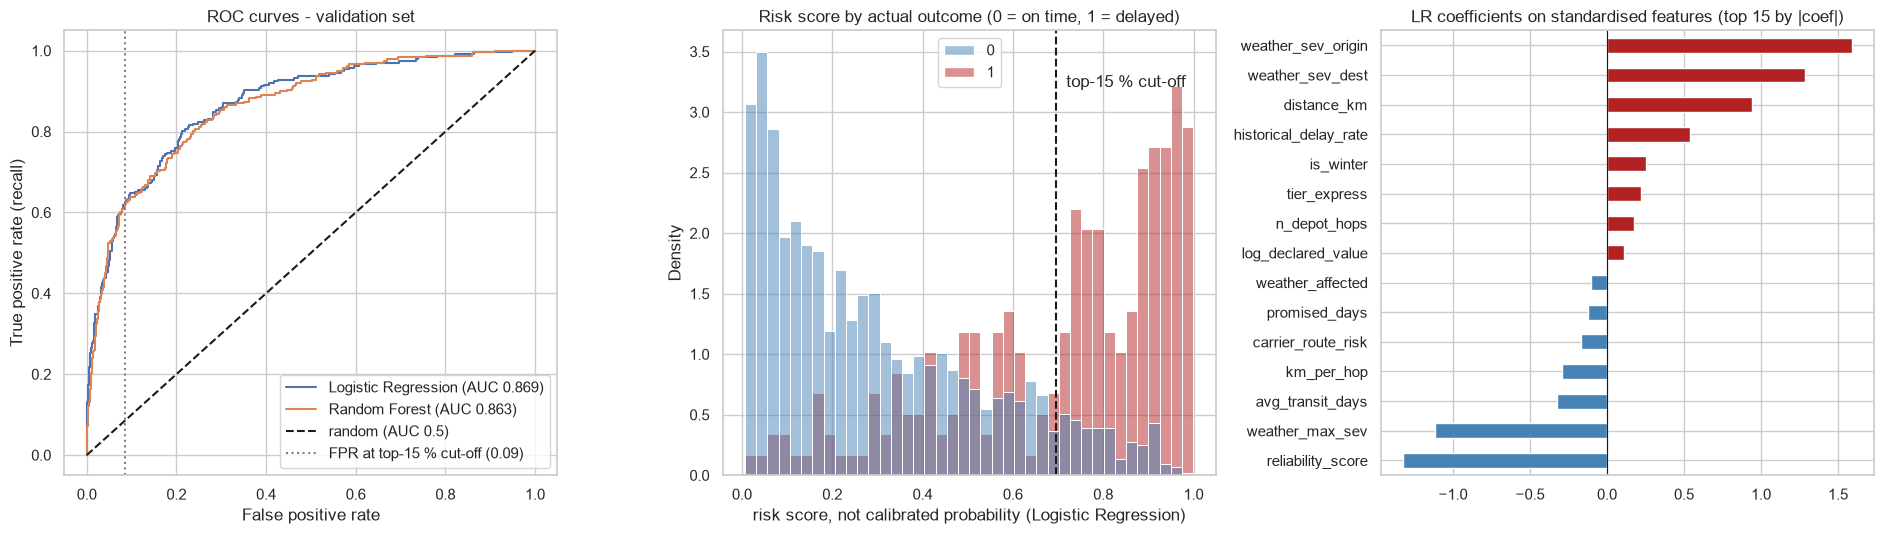

Random-forest impurity importance, top 10:
carrier_route_risk       0.190
weather_max_sev          0.094
weather_sev_origin       0.083
reliability_score        0.077
capacity_utilisation     0.066
weather_affected         0.056
stretched_carrier        0.053
distance_km              0.049
historical_delay_rate    0.043
weather_both_ends        0.036
dtype: float64

Average precision (AP) of Logistic Regression: 0.571   | no-skill baseline = prevalence 0.119



Permutation importance (drop in validation AUC when the column is shuffled), top 10:
weather_sev_origin       0.1898
reliability_score        0.1897
weather_sev_dest         0.1248
distance_km              0.1043
weather_max_sev          0.0610
historical_delay_rate    0.0385
tier_express             0.0062
is_winter                0.0057
avg_transit_days         0.0055
km_per_hop               0.0051
dtype: float64

LR without weather_max_sev: val AUC 0.868; weather coefficients become: {'weather_sev_origin': 0.76, 'weather_sev_dest': 0.47, 'weather_affected': -0.16, 'weather_both_ends': 0.22}
corr(weather_max_sev, weather_sev_origin) = 0.69 | corr(weather_max_sev, weather_sev_dest) = 0.7


In [15]:
# *(8 marks)* Produce:
# 1. ROC curves for all models
# 2. Score distribution by delay=0 vs delay=1
# 3. Feature importance / coefficients (top 15)
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
from sklearn.inspection import permutation_importance

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))

# 1. ROC curves (validation set) - the dashed vertical line marks the false-positive rate at the top-15 % cut-off
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_val, p)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_val, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', label='random (AUC 0.5)')
cut = np.quantile(best_prob, 0.85)
fpr15 = ((best_prob >= cut) & (y_val.values == 0)).sum() / (y_val.values == 0).sum()
ax[0].axvline(fpr15, c='grey', ls=':', label=f'FPR at top-15 % cut-off ({fpr15:.2f})')
print(f'top-15 % cut-off score = {cut:.3f}; false-positive rate at the cut-off = {fpr15:.3f}; '
      f'recall at the cut-off = {((best_prob >= cut) & (y_val.values == 1)).sum() / (y_val.values == 1).sum():.3f}')
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate (recall)'); ax[0].legend(); ax[0].set_title('ROC curves - validation set')

# 2. score distributions by actual outcome
sns.histplot(x=best_prob, hue=y_val.values, bins=40, stat='density', common_norm=False, ax=ax[1], palette={0: 'steelblue', 1: 'firebrick'})
ax[1].axvline(cut, c='k', ls='--'); ax[1].text(cut, ax[1].get_ylim()[1]*0.9, '  top-15 % cut-off', va='top')
ax[1].set_xlabel(f'risk score, not calibrated probability ({best_name})'); ax[1].set_title('Risk score by actual outcome (0 = on time, 1 = delayed)')

# 3. top-15 importance / coefficients of the chosen model
if best_name == 'Logistic Regression':
    imp = pd.Series(best_model.named_steps['clf'].coef_[0], index=feature_cols).sort_values(key=np.abs, ascending=False).head(15)
    imp.sort_values().plot(kind='barh', ax=ax[2], color=['firebrick' if v > 0 else 'steelblue' for v in imp.sort_values()])
    ax[2].set_title('LR coefficients on standardised features (top 15 by |coef|)'); ax[2].axvline(0, c='k', lw=.8)
else:
    imp = pd.Series(best_model.named_steps['clf'].feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
    imp.sort_values().plot(kind='barh', ax=ax[2], color='seagreen'); ax[2].set_title('RF impurity importance (top 15)')
plt.tight_layout(); plt.show()

# Random-forest importance describes split improvements in this fitted forest, not causal effects
rf_imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=feature_cols).sort_values(ascending=False)
print('Random-forest impurity importance, top 10:'); print(rf_imp.head(10).round(3))

# Extras recommended for a rare positive class
print(f'\nAverage precision (AP) of {best_name}: {average_precision_score(y_val, best_prob):.3f}   | no-skill baseline = prevalence {y_val.mean():.3f}')
pi = permutation_importance(best_model, X_val, y_val, scoring='roc_auc', n_repeats=10, random_state=RANDOM_STATE)
print('\nPermutation importance (drop in validation AUC when the column is shuffled), top 10:')
print(pd.Series(pi.importances_mean, index=feature_cols).sort_values(ascending=False).head(10).round(4))

# Sensitivity check: remove the maximum severity, which is derived from the two regional severities.
# This deterministic relationship is not the same as exact linear collinearity.
drop_cols = [c for c in feature_cols if c != 'weather_max_sev']
lr_nomax = clone(lr).fit(X_train[drop_cols], y_train)
print(f'\nLR without weather_max_sev: val AUC {roc_auc_score(y_val, lr_nomax.predict_proba(X_val[drop_cols])[:, 1]):.3f}; weather coefficients become:',
      pd.Series(lr_nomax.named_steps['clf'].coef_[0], index=drop_cols)[['weather_sev_origin','weather_sev_dest','weather_affected','weather_both_ends']].round(2).to_dict())
print('corr(weather_max_sev, weather_sev_origin) =', round(master[['weather_max_sev','weather_sev_origin']].corr().iloc[0,1], 2),
      '| corr(weather_max_sev, weather_sev_dest) =', round(master[['weather_max_sev','weather_sev_dest']].corr().iloc[0,1], 2))


**Interpret your diagnostics.**

- **ROC curves:** validation ROC-AUC is 0.869 for the logistic regression and 0.863 for the forest, and the curves overlap almost everywhere. At the top-15 % cut-off the logistic regression captures 62.6 % of actual delays while flagging 8.6 % of on-time shipments (capture divides by all delays; the false-positive rate by all on-time shipments).
- **Score distributions:** delayed shipments tend to score higher but the groups overlap, so the model makes mistakes. Because of the class weights the scores are inflated relative to the 12 % base rate; they are used as a ranking, and how closely they match observed delay rates has not been checked.
- **Feature importance:** weather, carrier reliability and route information dominate all three views. The largest standardised coefficients are origin severity +1.59, reliability −1.32, destination severity +1.28, maximum severity −1.12 and distance +0.94; the forest ranks `carrier_route_risk` first (0.19); permutation importance also highlights regional severity and reliability. Parcel attributes contribute little, matching their weak correlations in the EDA. The negative coefficient of `weather_max_sev` is not a real effect: it is the maximum of the two regional severities, so the three coefficients share one signal; removing it leaves validation AUC at 0.868 and all regional weather coefficients positive, so the weather group is read together. Average precision is 0.571 against a no-skill reference of 0.119.

**Business reading:** the model has learnt the network's structural weaknesses (carrier, corridor, weather, promise) rather than parcel properties, so carrier allocation, route design and service promises are the levers to investigate. These diagnostics describe predictive patterns, not what would happen after an operational change.


---
# SECTION 8 - Business Impact *(12 marks)*

Pooled validation set: 2,000 shipments, 238 actual delays (11.9%)
Model: flag 300 shipments; 149 were delayed. Capture = 62.6%; precision = 49.7%.
Random selection: expected capture = 15.0% (about 35.7 delays).
Capture lift over random selection = 4.17x
These are delays identified in historical data, not delays shown to have been prevented.
This ranks the whole validation set together. Daily top-15% performance has not yet been evaluated.
   Logistic Regression : capture 149/238 = 62.6%
   Random Forest       : capture 148/238 = 62.2%

Validation gross savings if every captured delay were prevented:
   model £6,705; random £1,606; incremental £5,099

At 85,000 shipments/month and the observed delay rate:
   about 10,124 delays; model identifies 6,338, random selection 1,519.
The scenarios below assume the same prevention rate for captured delays under both policies.


,prevention rate,model gross/month (£),random gross/month (£),incremental gross vs random/month (£),model net vs no action at £5/flag (£),break-even £/flag vs no action
0,1.00,285201.96,68333.62,216868.34,221451.96,22.35
1,0.50,142600.98,34166.81,108434.17,78850.98,11.18
2,0.25,71300.49,17083.41,54217.08,7550.49,5.59


The £22.35 full-prevention break-even figure is versus no intervention, using validation precision.
For two policies with the same flag count and cost per flag, intervention costs cancel in their comparison;
different costs or prevention rates would need to be included separately. None has been measured here.

Decile lift table (D1 = highest-scoring 10%):


,n,delays,delay_rate,lift,cum_capture
decile,,,,,
D1,200,112,0.560,4.706,0.471
D2,200,47,0.235,1.975,0.668
D3,200,35,0.175,1.471,0.815
D4,200,14,0.070,0.588,0.874
D5,200,13,0.065,0.546,0.929
D6,200,3,0.015,0.126,0.941
D7,200,7,0.035,0.294,0.971
D8,200,3,0.015,0.126,0.983
D9,200,3,0.015,0.126,0.996


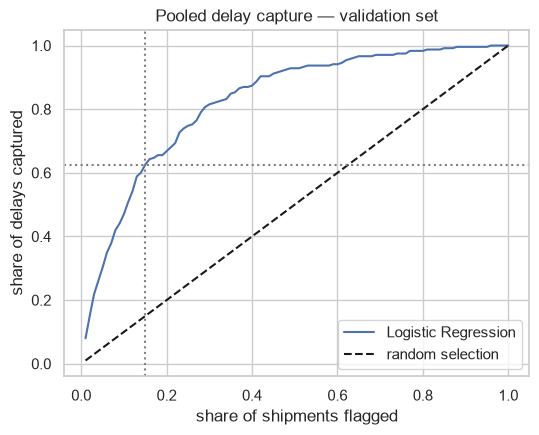

In [16]:
# *(7 marks)* Compute the delay capture rate at 15% intervention.
# Delay capture rate = actual delays in the flagged group / all actual delays.
# Compare random selection with model ranking, then estimate savings under explicit assumptions.

def capture_at(y_true, scores, frac=0.15):
    """Return delays captured, total delays, capture rate and number flagged."""
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    if len(y_true) != len(scores) or len(y_true) == 0:
        raise ValueError('y_true and scores must have the same non-zero length')
    if not 0 < frac <= 1:
        raise ValueError('frac must be between 0 and 1')
    k = int(np.ceil(frac * len(y_true)))
    top = np.argsort(-scores, kind='stable')[:k]  # exactly k rows; deterministic handling of ties
    caught, total = y_true[top].sum(), y_true.sum()
    return caught, total, caught / total if total else np.nan, k

caught, total, cap_model, k = capture_at(y_val, best_prob)
cap_random = k / len(y_val)                    # expected capture from random selection at the same budget
precision_15 = caught / k
print(f'Pooled validation set: {len(y_val):,} shipments, {total} actual delays ({y_val.mean():.1%})')
print(f'Model: flag {k} shipments; {caught} were delayed. Capture = {cap_model:.1%}; precision = {precision_15:.1%}.')
print(f'Random selection: expected capture = {cap_random:.1%} (about {cap_random * total:.1f} delays).')
print(f'Capture lift over random selection = {cap_model / cap_random:.2f}x')
print('These are delays identified in historical data, not delays shown to have been prevented.')
print('This ranks the whole validation set together. Daily top-15% performance has not yet been evaluated.')

for name, p in probs.items():
    c_, t_, cap_, _ = capture_at(y_val, p)
    print(f'   {name:20s}: capture {c_}/{t_} = {cap_:.1%}')

# Assumption: £45 saved per prevented delay (SLA penalty plus handling).
# The 100% prevention scenario is an upper bound, before intervention costs.
PENALTY = 45.0
print(f'\nValidation gross savings if every captured delay were prevented:')
print(f'   model £{caught * PENALTY:,.0f}; random £{cap_random * total * PENALTY:,.0f}; '
      f'incremental £{(caught - cap_random * total) * PENALTY:,.0f}')

# Illustrative extrapolation: future prevalence and pooled capture are assumed unchanged.
MONTHLY_SHIPMENTS = 85_000
monthly_delays = MONTHLY_SHIPMENTS * y.mean()
monthly_flags = MONTHLY_SHIPMENTS * cap_random
model_delays_identified = cap_model * monthly_delays
random_delays_identified = cap_random * monthly_delays
print(f'\nAt {MONTHLY_SHIPMENTS:,} shipments/month and the observed delay rate:')
print(f'   about {monthly_delays:,.0f} delays; model identifies {model_delays_identified:,.0f}, '
      f'random selection {random_delays_identified:,.0f}.')
print('The scenarios below assume the same prevention rate for captured delays under both policies.')

# £5 is an illustration, not an observed intervention cost. Every flagged shipment incurs the cost.
ILLUSTRATIVE_COST = 5.0
scenario_rows = []
for prevention_rate in [1.0, 0.5, 0.25]:
    model_gross = model_delays_identified * prevention_rate * PENALTY
    random_gross = random_delays_identified * prevention_rate * PENALTY
    scenario_rows.append({
        'prevention rate': prevention_rate,
        'model gross/month (£)': model_gross,
        'random gross/month (£)': random_gross,
        'incremental gross vs random/month (£)': model_gross - random_gross,
        'model net vs no action at £5/flag (£)': model_gross - monthly_flags * ILLUSTRATIVE_COST,
        # This per-flag ceiling uses validation precision, not the monthly extrapolation.
        'break-even £/flag vs no action': precision_15 * PENALTY * prevention_rate,
    })
display(pd.DataFrame(scenario_rows).round(2))
print('The £22.35 full-prevention break-even figure is versus no intervention, using validation precision.')
print('For two policies with the same flag count and cost per flag, intervention costs cancel in their comparison;')
print('different costs or prevention rates would need to be included separately. None has been measured here.')

# Decile table: ranking quality across the pooled validation score range.
tbl = pd.DataFrame({'y': y_val.values, 'score': best_prob}).sort_values(
    'score', ascending=False, kind='stable').reset_index(drop=True)
tbl['decile'] = pd.qcut(tbl.index, 10, labels=[f'D{i}' for i in range(1, 11)])
lift = tbl.groupby('decile', observed=True)['y'].agg(n='size', delays='sum')
lift['delay_rate'] = lift.delays / lift.n
lift['lift'] = lift.delay_rate / y_val.mean()
lift['cum_capture'] = lift.delays.cumsum() / lift.delays.sum()
print('\nDecile lift table (D1 = highest-scoring 10%):'); display(lift.round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
fracs = np.linspace(0.01, 1, 100)
ax.plot(fracs, [capture_at(y_val, best_prob, f)[2] for f in fracs], label=best_name)
ax.plot(fracs, fracs, 'k--', label='random selection')
ax.axvline(0.15, c='grey', ls=':'); ax.axhline(cap_model, c='grey', ls=':')
ax.set_xlabel('share of shipments flagged'); ax.set_ylabel('share of delays captured')
ax.set_title('Pooled delay capture — validation set'); ax.legend(); plt.show()


***(5 marks)* What is the business impact?**

Explain in plain language the value of flagging high-risk shipments vs random selection.
What would you recommend to SwiftRoute's Operations team?

Of the 300 validation shipments flagged (15 % of 2,000), 149 were actual delays: the model finds **62.6 % of all 238 delays** with 49.7 % precision, whereas flagging 300 shipments at random would find about 36 delays (15 %). The model therefore identifies about **4.2 times as many delays as random selection** for the same workload; the highest-scoring tenth alone has a 56 % delay rate and holds 47 % of all delays. The forest finds 148, so the two models are close on this measure.

**Finding a delay does not mean preventing it.** If every captured delay were prevented, the assumed £45 saving per delay gives £6,705 versus about £1,606 under random selection on the validation set. At 85,000 shipments a month, with the observed delay rate and capture rate, the incremental gross benefit over random selection would be about £217,000 per month at 100 % prevention or £108,000 at 50 %, before intervention costs. The break-even cost per flagged shipment is about £22 at 100 % prevention and £11 at 50 %, so cheap actions such as pre-alerts and carrier swaps pay for themselves while blanket tier upgrades probably do not. These are scenarios, not measured savings.

**Recommendations**

1. **Deploy the model as a daily worklist.** Score shipments at pickup and work the top 15 % each day; evaluate daily capture and precision on a later period, since the result above ranks the whole validation set together.
2. **Investigate the high-delay combinations.** Review C07/C08 express allocations and the long multi-hop London–Wales and London–Scotland corridors; check alternative capacity, costs and benefits before changing allocations or promised windows.
3. **Test the intervention.** Randomly assign eligible flagged shipments to intervention and control groups, compare outcomes and costs to measure how many delays an action actually prevents, then set the intervention budget from the break-even rule and monitor as described in Section 9.


---
## 8.2 - Save Your Model for Deployment

In [17]:
import joblib, json

# Save the fitted pipeline: median imputation, scaling (for LR), and classification.
# It accepts the 31 engineered feature columns, not raw shipment records.
# The joins and feature calculations in Sections 4–5 must run separately before scoring.
joblib.dump(best_model, 'model.pkl')
print('Model saved to model.pkl; input must contain the engineered feature columns.')

# Record the feature order and the simplified service-promise mapping.
# This metadata supports scoring but does not contain the feature-generation code or lookup tables.
with open('model_features.json', 'w') as f:
    json.dump({
        'model': best_name,
        'features': feature_cols,
        'promise_days': promise_days,
        'trained_on': '80% stratified random training split of shipments dated 2024-01-01..2026-06-19; random_state=42',
        'input_requirement': 'Engineered numeric features from Sections 4–5; raw-data joins and feature generation are outside this pipeline.'
    }, f, indent=2)

# Reload test: the saved object must reproduce the validation scores.
reloaded = joblib.load('model.pkl')
assert np.allclose(reloaded.predict_proba(X_val[feature_cols])[:, 1], best_prob)
print('Reload test passed: saved pipeline reproduces the validation scores.')
print('Saved steps:', list(reloaded.named_steps))


Model saved to model.pkl; input must contain the engineered feature columns.
Reload test passed: saved pipeline reproduces the validation scores.
Saved steps: ['impute', 'scale', 'clf']


---
# SECTION 9 - Monitoring for Drift in Production *(5 marks)*

**9.1** *(2 marks)* Propose how you would detect **input drift** on the live shipment stream. Which features are most likely to drift and what tests would you use?

Input drift means the shipments reaching the model differ from the reference (training) data, whether or not performance has changed yet. The features most likely to drift are carrier reliability and capacity utilisation (snapshot columns that change as contracts and fleets change), the carrier–tier mix (which will shift if Operations acts on this analysis and moves express parcels away from C07/C08), weather severity (seasonal), route mix and distance (network and client changes) and parcel weight, volume and declared value (new client types).

Tests, run weekly against the reference period: the **Population Stability Index (PSI)** per feature and for the model score, with the bands below 0.10 stable, 0.10–0.25 watch and above 0.25 investigate; a two-sample **Kolmogorov–Smirnov test** for continuous features; a **chi-square test** on category shares (tier, carrier, region); and data-quality checks on missing-value rates, unknown IDs and out-of-range values. The cell below computes PSI between the pre-2026 shipments and the 2026 H1 shipments (all values below 0.04, so the seasonal difference between the two periods is small), with quantile bins fixed on the reference, open outer bins, category shares for binary and few-valued features, and a score PSI from a model fitted on the earlier period only.

---

**9.2** *(3 marks)* Propose how you would detect **target drift** - i.e. the actual delay rate changing in ways the model no longer predicts correctly. What would trigger retraining?

Once delivery outcomes are complete, the **observed delay rate, ROC-AUC and delay capture at 15 %** would be tracked weekly, overall and by carrier, tier and route, against seasonal comparisons (the EDA showed a Q4/Q1 peak), together with whether the higher-scoring deciles still contain more delays. Starting alert rules: a sustained shift of roughly 3 percentage points in the delay rate over four weeks, AUC below 0.80 for two consecutive mature cohorts, or capture at 15 % below about 45 % (from 62.6 % at validation).

A sustained performance decline, a substantial network change (new carrier, route or depot) or a persistent unexplained population shift would trigger investigation: check data quality, lookup-table changes and operational changes first, then recalibrate or retrain if the evidence supports it. A candidate model would be retrained monthly on a recent 12–18 month window so that a full seasonal cycle is represented, validated on a later period before it replaces `model.pkl`, and built with the same discipline as here: features as known at pickup, labels only once delivery is confirmed. Interventions would be recorded alongside outcomes so that a successfully prevented delay is not counted as a model error.


In [18]:
# Illustration for 9.1: use disjoint reference and current periods.
# This cell does not change best_model or the saved deployment artifact.
from scipy.stats import ks_2samp
from sklearn.base import clone

def psi(reference, current, n_bins=10, discrete=False, epsilon=1e-6):
    """PSI on non-missing finite values; NaN when either sample has no such values.

    Use category shares for binary/ordinal features. For continuous features, retain
    reference quantile cut points and add infinite outer edges. A constant reference
    is compared using values below/equal to/above that reference value.
    Missing-value rates must be monitored separately.
    """
    reference = np.asarray(reference, dtype=float).ravel()
    current = np.asarray(current, dtype=float).ravel()
    reference = reference[np.isfinite(reference)]
    current = current[np.isfinite(current)]
    if len(reference) == 0 or len(current) == 0:
        return np.nan
    if n_bins < 2 or epsilon <= 0:
        raise ValueError('n_bins must be at least 2 and epsilon must be positive')

    reference_values = np.unique(reference)
    if discrete:
        # Include categories newly appearing in current data so drift is not discarded.
        categories = np.union1d(reference_values, np.unique(current))
        reference_counts = np.array([(reference == v).sum() for v in categories], dtype=float)
        current_counts = np.array([(current == v).sum() for v in categories], dtype=float)
    elif len(reference_values) == 1:
        value = reference_values[0]
        reference_counts = np.array([0, len(reference), 0], dtype=float)
        current_counts = np.array([(current < value).sum(), (current == value).sum(),
                                   (current > value).sum()], dtype=float)
    else:
        cut_points = np.unique(np.quantile(reference, np.linspace(0, 1, n_bins + 1)[1:-1]))
        # Do not replace the min/max unique quantiles: that collapsed binary data into one bin.
        edges = np.r_[-np.inf, cut_points, np.inf]
        reference_counts = np.histogram(reference, bins=edges)[0].astype(float)
        current_counts = np.histogram(current, bins=edges)[0].astype(float)

    reference_share = reference_counts / reference_counts.sum() + epsilon
    current_share = current_counts / current_counts.sum() + epsilon
    reference_share /= reference_share.sum()
    current_share /= current_share.sum()
    return float(np.sum((current_share - reference_share) * np.log(current_share / reference_share)))

watch = ['carrier_route_risk', 'weather_max_sev', 'reliability_score', 'capacity_utilisation',
         'distance_km', 'transit_slack_days', 'weight_kg', 'is_winter']
# Carrier snapshot values have only eight levels here, one per carrier.
discrete_features = {'weather_max_sev', 'is_winter', 'reliability_score', 'capacity_utilisation'}
reference_features = X.loc[train_t]       # pickups before 2026-01-01, as defined in Section 6
current_features = X.loc[~train_t]        # H1 2026
assert reference_features.index.intersection(current_features.index).empty
print(f'Disjoint periods: {len(reference_features):,} reference shipments before 2026; '
      f'{len(current_features):,} current shipments in H1 2026.')

rows = []
for c in watch:
    ref_values = reference_features[c]
    current_values = current_features[c]
    is_discrete = c in discrete_features
    ks_p = (ks_2samp(ref_values.dropna(), current_values.dropna()).pvalue
            if not is_discrete and ref_values.notna().any() and current_values.notna().any()
            else np.nan)
    rows.append({
        'feature': c,
        'PSI pre-2026 -> H1 2026': psi(ref_values, current_values, discrete=is_discrete),
        'KS p-value (continuous features)': ks_p,
        'reference missing share': ref_values.isna().mean(),
        'current missing share': current_values.isna().mean(),
    })

# A separate earlier-only LR provides both score distributions. Do not reuse the random-split
# model here: it was fitted on many H1-2026 rows. clone(lr) keeps its configuration, not its fit.
drift_lr = clone(lr).fit(reference_features, y.loc[reference_features.index])
reference_scores = drift_lr.predict_proba(reference_features)[:, 1]
current_scores = drift_lr.predict_proba(current_features)[:, 1]
rows.append({
    'feature': 'LR score (earlier-only fit)',
    'PSI pre-2026 -> H1 2026': psi(reference_scores, current_scores),
    'KS p-value (continuous features)': ks_2samp(reference_scores, current_scores).pvalue,
    'reference missing share': 0.0,
    'current missing share': 0.0,
})
display(pd.DataFrame(rows).set_index('feature').round(4))
print('PSI bands <0.10 / 0.10-0.25 / >0.25 are starting stable/watch/investigate rules.')
print('These periods differ in season and shipment mix. Distribution changes do not, by themselves,')
print('prove model deterioration or identify its cause. Use seasonal comparisons and outcome monitoring too.')


Disjoint periods: 8,077 reference shipments before 2026; 1,923 current shipments in H1 2026.


,PSI pre-2026 -> H1 2026,KS p-value (continuous features),reference missing share,current missing share
feature,,,,
carrier_route_risk,0.0032,0.9076,0.0000,0.000
weather_max_sev,0.0326,NaN,0.0000,0.000
reliability_score,0.0054,NaN,0.0000,0.000
capacity_utilisation,0.0054,NaN,0.0000,0.000
distance_km,0.0054,0.7173,0.0000,0.000
transit_slack_days,0.0023,0.5217,0.0000,0.000
weight_kg,0.0072,0.3037,0.0306,0.038
is_winter,0.0028,NaN,0.0000,0.000
LR score (earlier-only fit),0.0100,0.0256,0.0000,0.000


PSI bands <0.10 / 0.10-0.25 / >0.25 are starting stable/watch/investigate rules.
These periods differ in season and shipment mix. Distribution changes do not, by themselves,
prove model deterioration or identify its cause. Use seasonal comparisons and outcome monitoring too.


---
# EXTENSION *(10 marks)*

Attempt **both** tasks (5 marks each).

**E1** *(5 marks)* **Route-level analysis**: cluster routes by risk profile. Can you identify systematic weaknesses in SwiftRoute's network?

**E2** *(5 marks)* **SHAP**: for the top 10 highest-risk shipments in the validation set, use SHAP to explain exactly which factors are driving each prediction.

### E1 - Route-level analysis *(5 marks)*


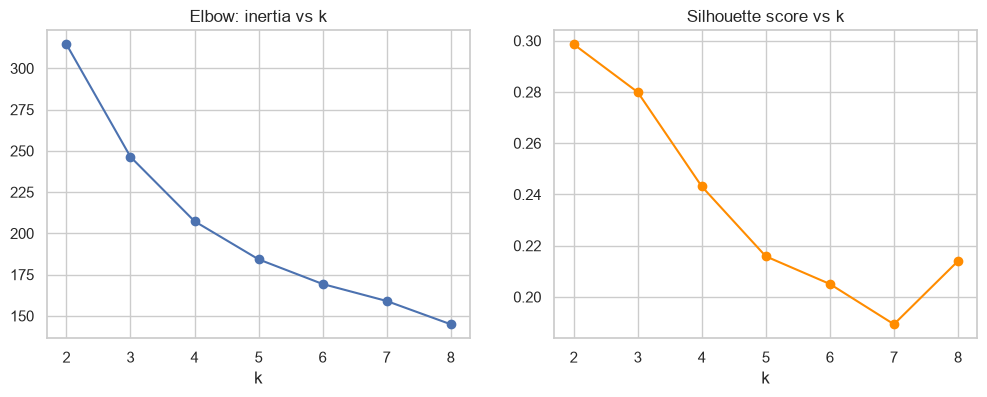

silhouette by k: {2: 0.299, 3: 0.28, 4: 0.243, 5: 0.216, 6: 0.205, 7: 0.189, 8: 0.214}
k chosen by silhouette: 2


,distance_km,hops,hist_rate,transit,express_share,weather_share,mean_reliability,stretched_share,mean_route_delay_rate,mean_shipments_per_route,n_routes,shipments,shipment_delay_rate
cluster,,,,,,,,,,,,,
0,230.943,1.543,0.125,2.044,0.251,0.289,0.782,0.44,0.067,167.0,35,5845,0.067
1,511.480,2.880,0.240,2.944,0.256,0.292,0.785,0.43,0.192,166.2,25,4155,0.193


routes per cluster by origin region:


cluster,0,1
origin_region,,
London,1,5
Midlands,6,1
North_East,4,3
North_West,7,1
Scotland,3,4
South_East,4,3
South_West,4,1
Wales,3,4
Yorkshire,3,3



k=3:


,distance_km,hops,hist_rate,mean_reliability,weather_share,mean_route_delay_rate,n_routes
c,,,,,,,
0,266.200,1.700,0.130,0.767,0.271,0.071,10
1,531.909,3.000,0.244,0.783,0.286,0.203,22
2,232.357,1.536,0.132,0.789,0.300,0.070,28



k=4:


,distance_km,hops,hist_rate,mean_reliability,weather_share,mean_route_delay_rate,n_routes
c,,,,,,,
0,252.111,1.667,0.127,0.767,0.267,0.067,9
1,350.786,2.286,0.178,0.789,0.340,0.120,14
2,197.526,1.316,0.115,0.789,0.279,0.058,19
3,552.056,3.000,0.253,0.782,0.274,0.209,18


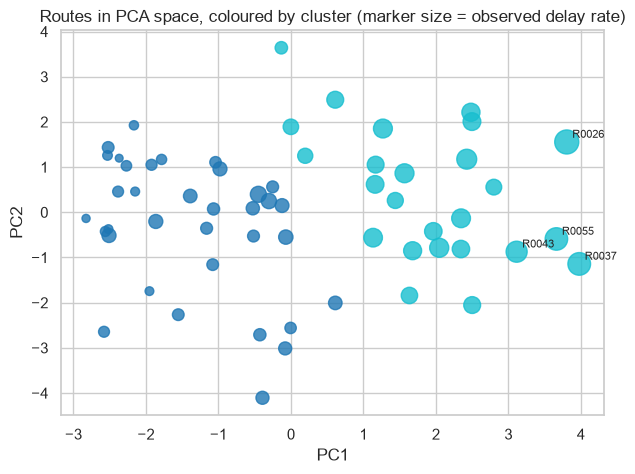

worst routes and their cluster:


,origin_region,dest_region,distance_km,hops,hist_rate,obs_delay,cluster
route_id,,,,,,,
R0026,London,Wales,698,3,0.331,0.350,1
R0037,Wales,London,758,3,0.279,0.308,1
R0055,Wales,South_East,618,3,0.352,0.303,1
R0043,London,Scotland,636,3,0.288,0.262,1
R0015,London,Yorkshire,549,3,0.286,0.232,1
R0001,London,North_East,480,3,0.247,0.211,1
R0018,Yorkshire,South_East,446,3,0.258,0.208,1
R0006,Yorkshire,South_West,412,3,0.250,0.206,1


In [19]:
# E1 - Route-level clustering: one row per route; inspect the elbow and choose k by silhouette.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

rt = (master.groupby('route_id').agg(
        distance_km=('distance_km','first'), hops=('n_depot_hops','first'), hist_rate=('historical_delay_rate','first'),
        transit=('avg_transit_days','first'), express_share=('tier_express','mean'), weather_share=('weather_affected','mean'),
        mean_reliability=('reliability_score','mean'), stretched_share=('stretched_carrier','mean'),
        obs_delay=('is_delayed','mean'), n=('is_delayed','size'))
      .join(routes.set_index('route_id')[['origin_region','dest_region']]))

# Clustering uses only the route's *profile* (structure, traffic mix, weather exposure, carriers used);
# the observed delay rate is kept aside and used afterwards to DESCRIBE the clusters, not to form them.
cl_cols = ['distance_km','hops','hist_rate','transit','express_share','weather_share','mean_reliability','stretched_share']
Z = StandardScaler().fit_transform(rt[cl_cols])          # scale units so kilometres do not dominate smaller-valued features

inertia, sil = {}, {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    inertia[k] = km.inertia_; sil[k] = silhouette_score(Z, km.labels_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(inertia), list(inertia.values()), 'o-'); ax[0].set_title('Elbow: inertia vs k'); ax[0].set_xlabel('k')
ax[1].plot(list(sil), list(sil.values()), 'o-', c='darkorange'); ax[1].set_title('Silhouette score vs k'); ax[1].set_xlabel('k'); plt.show()
print('silhouette by k:', {k: round(v, 3) for k, v in sil.items()})

k_best = max(sil, key=sil.get)
print('k chosen by silhouette:', k_best)
rt['cluster'] = KMeans(n_clusters=k_best, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
# Route-profile averages give every route equal weight, regardless of shipment count.
profile = rt.groupby('cluster')[cl_cols + ['obs_delay','n']].mean().rename(
    columns={'obs_delay': 'mean_route_delay_rate', 'n': 'mean_shipments_per_route'})
profile['n_routes'] = rt.groupby('cluster').size()
# Also report the pooled shipment rate, where busier routes contribute more observations.
cluster_totals = (master[['route_id', 'is_delayed']].join(rt['cluster'], on='route_id')
                  .groupby('cluster')['is_delayed'].agg(shipments='size', delays='sum'))
profile['shipments'] = cluster_totals['shipments']
profile['shipment_delay_rate'] = cluster_totals['delays'] / cluster_totals['shipments']
display(profile.round(3))
print('routes per cluster by origin region:'); display(pd.crosstab(rt.origin_region, rt.cluster))

# Compare finer partitions: inspect which route profiles change when k is 3 or 4.
for k in (3, 4):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
    print(f'\nk={k}:'); display(rt.assign(c=lab).groupby('c')[['distance_km','hops','hist_rate','mean_reliability','weather_share','obs_delay']].mean().rename(columns={'obs_delay': 'mean_route_delay_rate'}).round(3).assign(n_routes=pd.Series(lab).value_counts().sort_index().values))

pcs = PCA(n_components=2).fit_transform(Z)
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(pcs[:, 0], pcs[:, 1], c=rt['cluster'], cmap='tab10', s=rt['obs_delay']*800 + 20, alpha=.8)
for (rid, r), (x_, y_) in zip(rt.iterrows(), pcs):
    if r.obs_delay > 0.25: ax.annotate(rid, (x_, y_), textcoords='offset points', xytext=(4, 3), fontsize=8)
ax.set_title('Routes in PCA space, coloured by cluster (marker size = observed delay rate)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); plt.show()
print('worst routes and their cluster:'); display(rt.sort_values('obs_delay', ascending=False).head(8)[['origin_region','dest_region','distance_km','hops','hist_rate','obs_delay','cluster']].round(3))


**E1 - What the route clustering shows**

Each of the 60 routes is summarised by eight inputs covering structure (distance, depot hops, typical transit), historical risk, service mix, weather exposure and carrier mix. The inputs were standardised so that large units such as kilometres do not dominate the distance calculation, then k-means was fitted; the current observed delay rate was kept out of the inputs and used afterwards to describe the groups. Inertia falls monotonically with k, so the elbow alone is ambiguous; the silhouette score is highest at **k = 2** (0.299, then 0.280 at k = 3 and 0.243 at k = 4), and k = 3 or 4 mainly split the routes further by distance.

| Route group | Routes | Mean distance | Mean depot hops | Mean observed route delay rate |
|---|---:|---:|---:|---:|
| Longer, multi-hop routes | 25 | 511 km | 2.9 | 19.2 % |
| Shorter routes | 35 | 231 km | 1.5 | 6.7 % |

Weighting by shipments instead of routes gives 6.7 % and 19.3 %, the same gap. Average carrier reliability (0.79 vs 0.78) and weather exposure (about 29 %) are the same in both groups, so the systematic weakness the clustering points to is **route length and the number of depot hops**: long multi-hop corridors run at about three times the delay rate of short ones whoever carries the parcel. The carrier problem seen in 3.4 (C07/C08) cuts across routes rather than belonging to particular corridors. A silhouette around 0.30 indicates modest separation, so k = 2 is a coarse summary of 60 routes rather than proof of two distinct route types, and the clusters show where delays concentrate, not that redesigning a corridor will prevent them; the long multi-hop corridors are the first candidates for fewer transfers or revised promised windows.


### E2 - SHAP explanations *(5 marks)*


These explanations show which inputs move the fitted model score up or down.
They do not prove what caused a delay or what an intervention would prevent.
Logistic Regression: contributions are in model log-odds units; baseline (mean model log-odds over the validation background) = -0.921.
Additivity check across all validation rows: True
A model score between 0 and 1 is not automatically a calibrated delay probability.


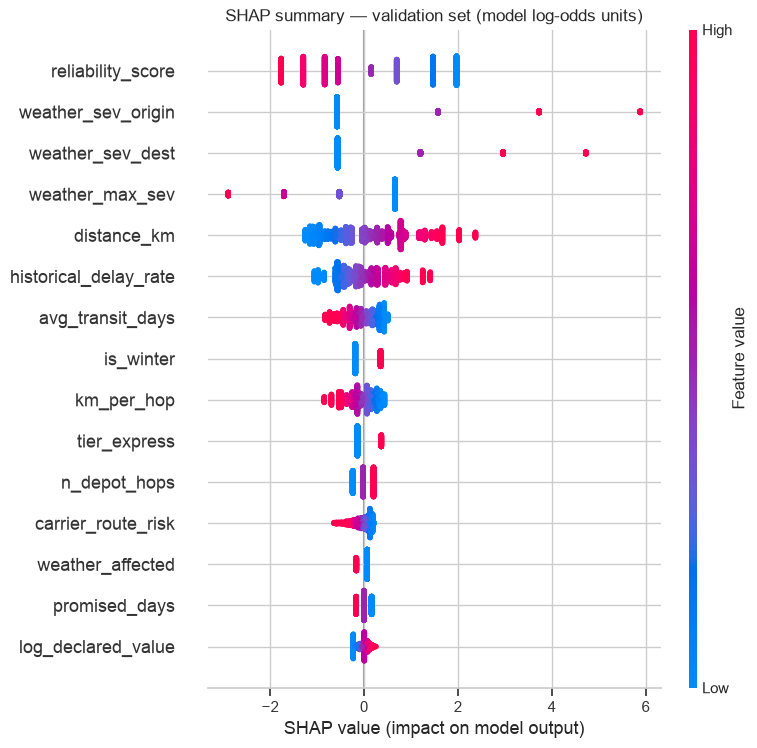

Top four individual contributions per shipment (model log-odds units):


,top contributions
SH0006009,"{'weather_sev_origin': 5.883, 'weather_sev_dest': 2.965, 'weather_max_sev': -2.892, 'reliability_score': 1.971}"
SH0005982,"{'weather_sev_origin': 5.883, 'weather_sev_dest': 4.728, 'weather_max_sev': -2.892, 'reliability_score': 1.471}"
SH0006549,"{'weather_sev_origin': 5.883, 'weather_sev_dest': 2.965, 'weather_max_sev': -2.892, 'reliability_score': 1.471}"
SH0003958,"{'weather_sev_origin': 3.731, 'weather_sev_dest': 2.965, 'reliability_score': 1.971, 'weather_max_sev': -1.708}"
SH0006254,"{'weather_sev_origin': 5.883, 'weather_sev_dest': 2.965, 'weather_max_sev': -2.892, 'reliability_score': 1.471}"
SH0004068,"{'weather_sev_origin': 3.731, 'weather_max_sev': -1.708, 'reliability_score': 1.471, 'weather_sev_dest': 1.202}"
SH0002014,"{'weather_sev_origin': 3.731, 'weather_sev_dest': 2.965, 'weather_max_sev': -1.708, 'reliability_score': 1.471}"
SH0007186,"{'weather_sev_origin': 5.883, 'weather_max_sev': -2.892, 'reliability_score': 1.971, 'distance_km': 1.553}"
SH0001164,"{'weather_sev_origin': 5.883, 'weather_sev_dest': 2.965, 'weather_max_sev': -2.892, 'reliability_score': -0.837}"
SH0000771,"{'weather_sev_origin': 5.883, 'weather_max_sev': -2.892, 'reliability_score': 1.471, 'weather_sev_dest': -0.561}"


Summed contributions (model log-odds units); baseline + total reconstructs the explained output:


,weather,carrier,route,promise,calendar,parcel,total,model_score,actual_delay
SH0006009,5.723,1.459,1.207,-0.148,0.234,0.007,8.482,0.999,1
SH0005982,7.485,1.357,-1.127,-0.286,-0.011,0.020,7.438,0.999,1
SH0006549,5.723,1.213,0.634,-0.286,-0.325,0.380,7.339,0.998,1
SH0003958,4.754,1.455,1.134,-0.287,0.260,-0.075,7.242,0.998,1
SH0006254,5.723,1.153,0.769,-0.148,-0.289,-0.086,7.122,0.998,1
SH0004068,2.991,1.142,0.961,0.524,0.540,0.154,6.312,0.995,0
SH0002014,4.754,1.153,0.769,-0.148,-0.313,-0.019,6.197,0.995,1
SH0007186,2.269,1.491,1.179,0.524,0.295,0.071,5.829,0.993,1
SH0001164,5.723,-0.657,0.634,-0.148,-0.018,0.010,5.544,0.990,1
SH0000771,2.269,1.153,0.769,0.524,0.569,0.077,5.361,0.988,1



One explanation per shipment:
• SH0006009 — model score 0.999, observed delay = 1; Midlands→Wales. Contributions UP: weather +5.72 (pickup-day severity 3 at origin / 2 at destination); carrier +1.46 (BudgetShip, reliability 0.59); route +1.21 (492 km, 3 depot stops, history 25% late); calendar +0.23 (Jan 2025, winter). Contributions DOWN: promise -0.15 (standard, simplified slack +0.2 days).
• SH0005982 — model score 0.999, observed delay = 1; South_West→South_East. Contributions UP: weather +7.49 (pickup-day severity 3 at origin / 3 at destination); carrier +1.36 (GreenRoute, reliability 0.64). Contributions DOWN: route -1.13 (154 km, 1 depot stop, history 11% late); promise -0.29 (economy, simplified slack +3.3 days).
• SH0006549 — model score 0.998, observed delay = 1; Wales→North_West. Contributions UP: weather +5.72 (pickup-day severity 3 at origin / 2 at destination); carrier +1.21 (GreenRoute, reliability 0.64); route +0.63 (432 km, 3 depot stops, history 17% late); parcel +0.3

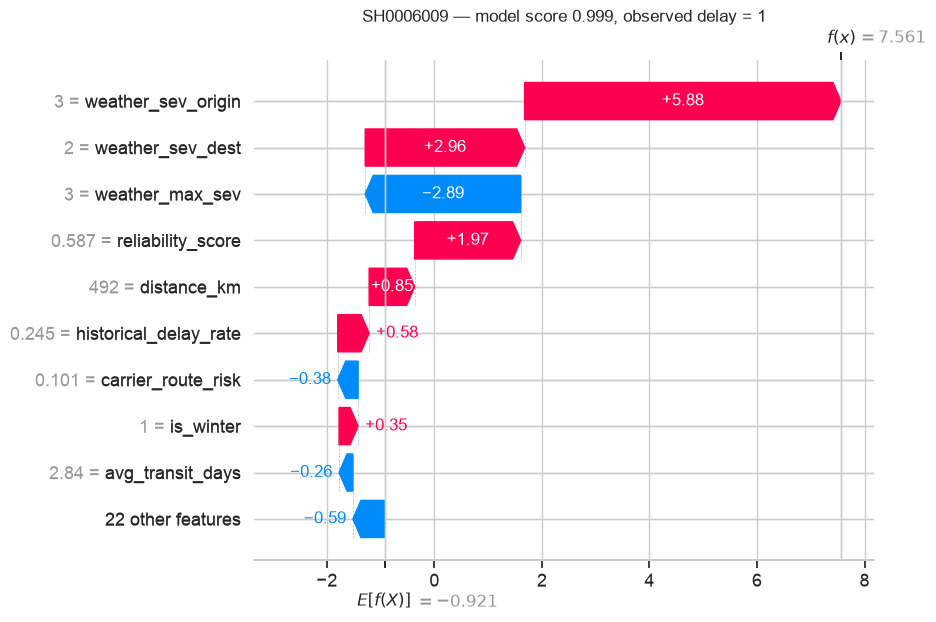

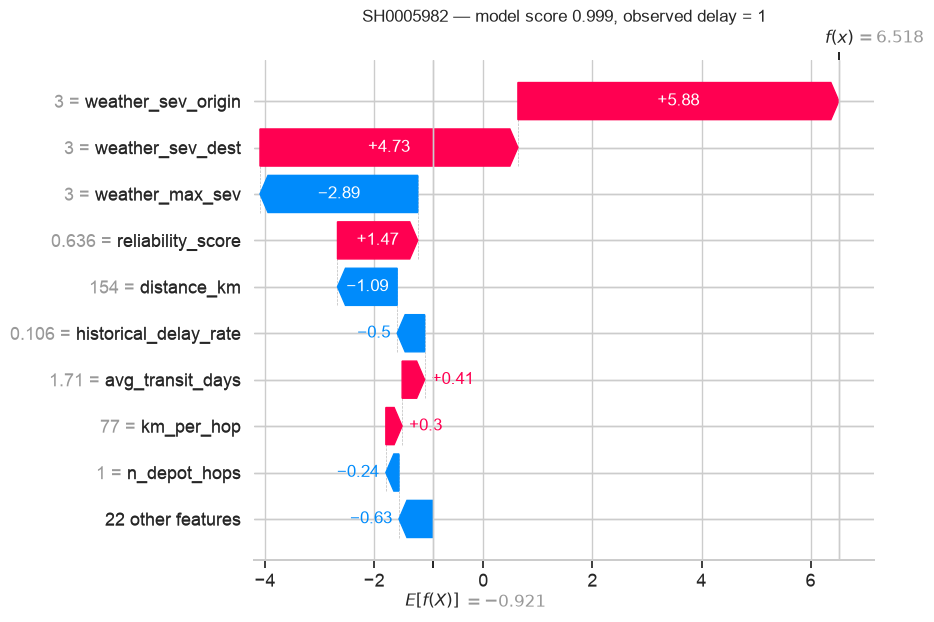

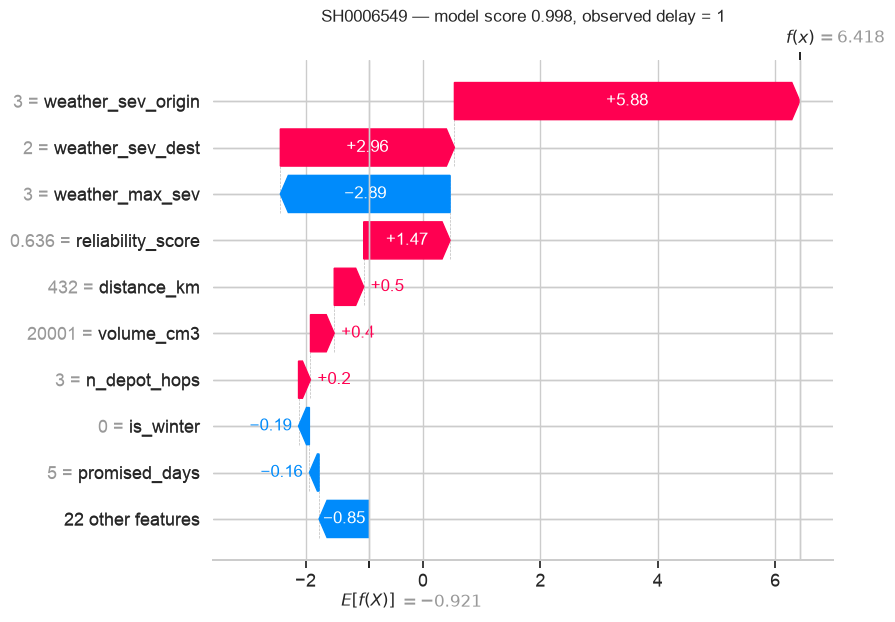

In [20]:
# E2 - Explain the ten highest-scoring validation shipments.
import warnings
from tqdm import TqdmWarning

# This optional progress-bar notice does not affect explanations; keep other warnings visible.
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='IProgress not found.*', category=TqdmWarning)
    import shap

print('These explanations show which inputs move the fitted model score up or down.')
print('They do not prove what caused a delay or what an intervention would prevent.')

# Explain the classifier's actual preprocessed inputs, keeping row and column order.
X_val_imp = pd.DataFrame(best_model.named_steps['impute'].transform(X_val),
                         columns=feature_cols, index=X_val.index)
classifier = best_model.named_steps['clf']
if best_name == 'Random Forest':
    explainer = shap.TreeExplainer(classifier)
    raw_sv = explainer.shap_values(X_val_imp)
    positive_class = list(classifier.classes_).index(1)
    if isinstance(raw_sv, list):
        sv = raw_sv[positive_class]
    else:
        raw_sv = np.asarray(raw_sv)
        sv = raw_sv[..., positive_class] if raw_sv.ndim == 3 else raw_sv
    expected = np.asarray(explainer.expected_value).ravel()
    base = float(expected[positive_class] if len(expected) > 1 else expected[0])
    units = 'probability units'
    baseline_description = "TreeExplainer's expected class-1 score"
    explained_output = best_prob             # sklearn RandomForest SHAP sums to class probability
    contribution_threshold = 0.01
else:
    X_val_s = pd.DataFrame(best_model.named_steps['scale'].transform(X_val_imp.to_numpy()),
                          columns=feature_cols, index=X_val.index)
    # Valid interventional/Independent SHAP: beta_i * (z_i - mean_background(z_i)).
    # The background defines the comparison population; it does not use the outcome labels.
    masker = shap.maskers.Independent(X_val_s, max_samples=len(X_val_s))
    explainer = shap.LinearExplainer(classifier, masker)
    sv = explainer.shap_values(X_val_s)
    base = float(np.asarray(explainer.expected_value).ravel()[0])
    units = 'model log-odds units'
    baseline_description = 'mean model log-odds over the validation background'
    explained_output = classifier.decision_function(X_val_s.to_numpy())
    contribution_threshold = 0.1

sv = np.asarray(sv)
additivity_ok = np.allclose(base + sv.sum(axis=1), explained_output, rtol=1e-6, atol=1e-6)
assert additivity_ok, 'SHAP contributions must reconstruct the explained model output'
print(f'{best_name}: contributions are in {units}; baseline ({baseline_description}) = {base:.3f}.')
print('Additivity check across all validation rows:', additivity_ok)
print('A model score between 0 and 1 is not automatically a calibrated delay probability.')

shap.summary_plot(sv, X_val_imp, max_display=15, show=False)
plt.title(f'SHAP summary — validation set ({units})'); plt.show()

top10 = np.argsort(-best_prob, kind='stable')[:10]
ids = master.loc[X_val.index[top10], 'shipment_id'].values
contrib = pd.DataFrame(sv[top10], columns=feature_cols, index=ids)
print(f'Top four individual contributions per shipment ({units}):')
with pd.option_context('display.max_colwidth', None):
    display(contrib.apply(lambda r: r.sort_values(key=np.abs, ascending=False).head(4).round(3).to_dict(),
                          axis=1).to_frame('top contributions'))

# Summing related columns is a presentation choice. It does not remove feature dependence,
# make the attribution causal, or turn these into separately estimated group Shapley values.
GROUPS = {
    'weather': ['weather_sev_origin','weather_sev_dest','weather_max_sev','weather_affected','weather_both_ends'],
    'carrier': ['reliability_score','capacity_utilisation','stretched_carrier','carrier_route_risk'],
    'route': ['distance_km','n_depot_hops','historical_delay_rate','avg_transit_days','km_per_hop'],
    'promise': ['tier_express','tier_economy','promised_days','transit_slack_days'],
    'calendar': ['month','is_winter','day_of_week','is_weekend'],
    'parcel': ['weight_kg','volume_cm3','declared_value','is_business','weight_missing','value_missing',
               'volume_to_weight','log_weight','log_declared_value'],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(feature_cols)
grouped = pd.DataFrame({g: contrib[cols].sum(axis=1) for g, cols in GROUPS.items()})
grouped['total'] = contrib.sum(axis=1)        # calculate before display rounding
grouped['model_score'] = best_prob[top10]
grouped['actual_delay'] = y_val.iloc[top10].values
print(f'Summed contributions ({units}); baseline + total reconstructs the explained output:')
display(grouped.round(3))

print('\nOne explanation per shipment:')
cname = carriers.set_index('carrier_id')['carrier_name']
for sid, i in zip(ids, top10):
    m = master.loc[X_val.index[i]]
    g = grouped.loc[sid, list(GROUPS)].sort_values(key=np.abs, ascending=False)
    detail = {
        'weather': f"pickup-day severity {int(m.weather_sev_origin)} at origin / {int(m.weather_sev_dest)} at destination",
        'carrier': f"{cname[m.carrier_id]}, reliability {m.reliability_score:.2f}",
        'route': f"{int(m.distance_km)} km, {int(m.n_depot_hops)} depot stop{'s' if m.n_depot_hops != 1 else ''}, history {m.historical_delay_rate:.0%} late",
        'promise': f"{m.service_tier}, simplified slack {m.transit_slack_days:+.1f} days",
        'calendar': f"{m.pickup_date.strftime('%b %Y')}{', winter' if m.is_winter else ''}",
        'parcel': f"{'weight missing' if m.weight_missing else f'{m.weight_kg:.1f} kg'}, value {'missing' if m.value_missing else f'£{m.declared_value:.0f}'}",
    }
    ups = [f"{k} {g[k]:+.2f} ({detail[k]})" for k in g.index if g[k] >= contribution_threshold]
    downs = [f"{k} {g[k]:+.2f} ({detail[k]})" for k in g.index if g[k] <= -contribution_threshold]
    print(f"• {sid} — model score {best_prob[i]:.3f}, observed delay = {int(y_val.iloc[i])}; "
          f"{m.origin_region}→{m.dest_region}. Contributions UP: {'; '.join(ups) or 'none above display threshold'}."
          + (f" Contributions DOWN: {'; '.join(downs)}." if downs else ''))

print('\nMean absolute contribution across these ten shipments (a local summary, not all shipments):')
print(contrib.abs().mean().sort_values(ascending=False).head(8).round(3))

for i in top10[:3]:
    shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base,
                         data=X_val_imp.iloc[i].values, feature_names=feature_cols),
                         max_display=10, show=False)
    plt.title(f'{master.loc[X_val.index[i], "shipment_id"]} — model score {best_prob[i]:.3f}, '
              f'observed delay = {int(y_val.iloc[i])}'); plt.show()


**E2 - What SHAP says about the ten highest-scoring shipments**

For all ten selected shipments, **weather makes the largest positive contribution** to the logistic model's score: all have severity-2 or -3 weather at the origin on the pickup day and eight also at the destination. **The carrier is the second driver**: nine of the ten use GreenRoute or BudgetShip, whose reliability and capacity features raise their scores; for SH0001164 (SureDeliver) the carrier contribution is negative (about −0.66), but weather and route still place it in the top ten. **Route difficulty is third**: the long three-hop routes add to the scores, while the short route of SH0005982 lowers its score relative to the background. Promise, calendar and parcel contributions are smaller. Nine of the ten were actually delayed.

The contributions are in log-odds units: the baseline (−0.92, the average log-odds over the validation set) plus a shipment's contributions reconstructs its model log-odds exactly, and the sigmoid converts that back to the score. For readability the per-feature contributions are also summed into six business groups (weather, carrier, route, promise, calendar, parcel); because the collinear weather columns share one signal, the weather group should be read as a whole rather than coefficient by coefficient. These explanations describe how the fitted model arrives at each score, not the real-world cause of each delay or what a carrier swap would have prevented; that requires the intervention trial proposed in Section 8.
